# AE611 — Two-Dimensional Vortex Panel Method

**Constant-strength and linear-strength formulations**  
**Student:** Anbu Cheran S.  
**Programme:** M.Tech Aerospace Engineering — Aerodynamics and Flight Mechanics  
**Date:** 16 November 2026

This report notebook is prepared from the saved outputs and implementation in the uploaded Jupyter notebook. Numerical values and figures are reproduced from that notebook; unresolved inconsistencies are identified explicitly.

## Abstract

Constant- and linear-strength 2D vortex panel methods were implemented and applied to a circular cylinder, NACA 0012 and NACA 4412. The work includes cylinder verification, airfoil convergence, pressure distributions, lift trends, panel-spacing and thickness studies. Numerical results, unresolved inconsistencies and corrections are reported below.

## 1. Assignment requirements

1. Constant- and linear-strength algorithms.
2. Python functions `vortex_panel_method_0()` and `vortex_panel_method_1()`.
3. Cylinder verification and convergence.
4. Symmetric/non-symmetric airfoil convergence and panel-spacing study.
5. Airfoil characteristics and Cₚ distributions.
6. Thickness-related prediction limitation.
7. References and AI acknowledgement.

## 2. Numerical formulation

The contour is discretised into straight panels. Panel endpoints define the geometry and panel midpoints are control points. Influence coefficients are resolved into normal and tangential components. The no-penetration condition is imposed at control points, and a Kutta condition is applied at the airfoil trailing edge.

$$C_p=1-\left(\frac{V_t}{V_\infty}\right)^2$$

### Constant-strength formulation
There are N unknown panel strengths. The corrected airfoil assembly retains all N normal-flow equations and appends one Kutta equation, giving an (N+1)× N matrix solved using truncated SVD (`rcond=1e-3`).

### Linear-strength formulation
There are N+1 nodal strengths for N panels. The N normal-flow equations and one Kutta equation form a square (N+1)×(N+1) system, solved using the linear method's own solver.

## 2A. Governing and implementation formulas used in this assignment

This section records the mathematical relations implemented in the submitted Python functions. The notation follows the code: N is the number of panels, Sj is the length of panel j, θ_j is its orientation, and (xc_ᵢ,yc_ᵢ) is control point i.

### 2A.1 Panel geometry

For consecutive contour nodes (xj,yj) and (xj₊₁,yj₊₁), the panel length and orientation are

$$
S_j=\sqrt{(x_{j+1}-x_j)^2+(y_{j+1}-y_j)^2},
\qquad
\theta_j=\operatorname{atan2}(y_{j+1}-y_j,x_{j+1}-x_j).
$$

The control point is the midpoint:

$$
x_{c_j}=\frac{x_j+x_{j+1}}{2},\qquad
y_{c_j}=\frac{y_j+y_{j+1}}{2}.
$$

For the counter-clockwise contour convention used by `define_panels`, the code defines

$$
\mathbf t_j=(\cos\theta_j,\sin\theta_j),\qquad
\mathbf n_j=(\sin\theta_j,-\cos\theta_j).
$$

The signed polygon area is checked using the shoelace formula:

$$
A_s=\frac12\sum_{j=0}^{N-1}(x_jy_{j+1}-x_{j+1}y_j).
$$

The implementation requires As>0, i.e. counter-clockwise node ordering.

### 2A.2 Transformation to a source-panel local coordinate system

For control point i relative to the first endpoint of source panel j,

$$
\Delta x=x_{c_i}-x_j,\qquad \Delta y=y_{c_i}-y_j.
$$

The local coordinates used in the influence-integral functions are

$$
x=\Delta x\cos\theta_j+\Delta y\sin\theta_j,
\qquad
y=-\Delta x\sin\theta_j+\Delta y\cos\theta_j.
$$

The relative orientation between observation and source panels is

$$
\Delta\theta_{ij}=\theta_i-\theta_j.
$$

### 2A.3 Influence integrals

For a source panel of length S, the off-diagonal influence integrals in `calculate_influence_integralss()` are

$$
I_0=\operatorname{atan2}\!\left(Sy,\;x(x-S)+y^2\right),
$$

$$
J_0=\frac12\ln\left(\frac{x^2+y^2}{(x-S)^2+y^2}\right),
$$

$$
I_1=xI_0-yJ_0,
\qquad
J_1=xJ_0-S+yI_0.
$$

The general integral routine uses the equivalent angle difference
I₀=atan2(y,x-S)-atan2(y,x), with the same J₀,I₁,J₁ definitions. The code explicitly assigns self-influence terms to avoid evaluating the singular expressions at i=j.

### 2A.4 Linear-strength endpoint influence coefficients

The linear-strength formulation interpolates vortex strength between the two endpoints of each source panel. The local tangential coefficients are

$$
U_L=-\frac{I_0-I_1/S}{2\pi},\qquad
U_R=-\frac{I_1}{2\pi S},
$$

and the local normal coefficients are

$$
W_L=\frac{J_0-J_1/S}{2\pi},\qquad
W_R=\frac{J_1}{2\pi S}.
$$

After rotating into the observation-panel frame, the code forms

$$
A_L=U_L\sin\Delta\theta-W_L\cos\Delta\theta,
\qquad
A_R=U_R\sin\Delta\theta-W_R\cos\Delta\theta,
$$

$$
T_L=U_L\cos\Delta\theta+W_L\sin\Delta\theta,
\qquad
T_R=U_R\cos\Delta\theta+W_R\sin\Delta\theta.
$$

The left and right contributions are accumulated into columns j and j+1 of the normal matrix Aₙ and tangential matrix Tt. Consequently, for N panels these matrices have dimensions N×(N+1).

For a self-panel, the code uses
UL=UR=1/4, WL=1/(2π), and WR=-1/(2π).

### 2A.5 Constant-strength influence coefficients

For the constant-strength formulation, the off-diagonal local coefficients are

$$
U=-\frac{I_0}{2\pi},\qquad W=\frac{J_0}{2\pi}.
$$

Their normal and tangential projections are

$$
A_{n,ij}=U\sin\Delta\theta_{ij}-W\cos\Delta\theta_{ij},
$$

$$
T_{t,ij}=U\cos\Delta\theta_{ij}+W\sin\Delta\theta_{ij}.
$$

For a self-panel the code sets U=1/2, W=0. Both constant-strength matrices have dimensions N× N.

### 2A.6 No-penetration boundary condition and freestream terms

The normal component of the freestream at control point i is represented in the code by

$$
V_{n,\infty,i}=V_\infty\sin(\theta_i-\alpha).
$$

The discrete no-penetration equations are therefore

$$
A_n\boldsymbol\gamma+
V_\infty
\begin{bmatrix}
\sin(\theta_1-\alpha)\\
\vdots\\
\sin(\theta_N-\alpha)
\end{bmatrix}
=\mathbf 0.
$$

Equivalently, the right-hand side is

$$
b_i=-V_\infty\sin(\theta_i-\alpha).
$$

### 2A.7 Kutta condition and assembled systems

The trailing-edge closure implemented in both methods is

$$
\gamma_1+\gamma_{N+1}=0
$$

for the linear nodal-strength formulation, and

$$
\gamma_1+\gamma_N=0
$$

for the constant panel-strength formulation.

**Linear-strength system:** N normal-flow equations plus one Kutta equation give

$$
\begin{bmatrix}
A_n\\
1\;0\;\cdots\;0\;1
\end{bmatrix}
\boldsymbol\gamma
=
\begin{bmatrix}
-V_\infty\sin(\theta_1-\alpha)\\
\vdots\\
-V_\infty\sin(\theta_N-\alpha)\\
0
\end{bmatrix},
$$

an (N+1)×(N+1) system.

**Constant-strength system:** the implementation retains all N normal-flow equations and appends the Kutta row:

$$
M_c=
\begin{bmatrix}
A_n\\
1\;0\;\cdots\;0\;1
\end{bmatrix},\qquad
M_c\boldsymbol\gamma=\mathbf b_c,
$$

where Mc is (N+1)× N. This is rectangular and is not suitable for `numpy.linalg.solve`.

### 2A.8 Solving the constant-strength rectangular system

The code uses singular-value decomposition:

$$
M_c=U\Sigma V^T.
$$

Singular values are retained only if

$$
\sigma_k>r_{\mathrm{cond}}\sigma_{\max},
\qquad r_{\mathrm{cond}}=10^{-3}.
$$

The truncated-SVD solution is

$$
\boldsymbol\gamma=
V_r\Sigma_r^{-1}U_r^T\mathbf b_c.
$$

The cutoff regularises small singular directions. It also means the solution is a truncated least-squares solution; it is not the same as solving a square system exactly.

### 2A.9 Tangential velocity and pressure coefficient

For either method, the panel tangential velocity is

$$
V_{t,i}=V_\infty\cos(\alpha-\theta_i)
+\sum_j T_{t,ij}\gamma_j.
$$

In matrix notation,

$$
\mathbf V_t=V_\infty\cos(\alpha-\boldsymbol\theta)+T_t\boldsymbol\gamma.
$$

The pressure coefficient follows from Bernoulli's equation for steady, incompressible, inviscid flow:

$$
\boxed{C_{p,i}=1-\left(\frac{V_{t,i}}{V_\infty}\right)^2}.
$$

### 2A.10 Boundary-condition and Kutta diagnostics

The normal-flow residual vector calculated in the wrappers is

$$
\mathbf r_n=A_n\boldsymbol\gamma+
V_\infty\sin(\boldsymbol\theta-\alpha).
$$

Its RMS value is

$$
r_{n,\mathrm{RMS}}=
\sqrt{\frac1N\sum_{i=1}^{N}r_{n,i}^2}.
$$

The Kutta-condition error reported by the code is

$$
e_K=\gamma_1+\gamma_{\mathrm{TE,other}}.
$$

A small residual verifies satisfaction of the imposed discrete equations; it does not by itself establish that the physical model is accurate.

### 2A.11 Pressure-force integration and wind-axis coefficients

The code first integrates pressure over the panel normals:

$$
C_x=-\sum_{i=1}^{N}C_{p,i}n_{x,i}S_i,
\qquad
C_y=-\sum_{i=1}^{N}C_{p,i}n_{y,i}S_i.
$$

The body-axis force coefficients are transformed into wind axes as

$$
\boxed{C_D=C_x\cos\alpha+C_y\sin\alpha},
$$

$$
\boxed{C_L=-C_x\sin\alpha+C_y\cos\alpha}.
$$

Here Cᴅ is the pressure contribution obtained from the inviscid surface-pressure integration. It is not total drag because skin-friction drag is absent from the model.

### 2A.12 Cylinder analytical solution and convergence errors

For a circular cylinder in uniform potential flow, the analytical surface pressure coefficient used by the notebook is

$$
\boxed{C_{p,\mathrm{exact}}=1-4\sin^2(\phi-\alpha)}
$$

where φ is the polar angle of the control point. The code calculates

$$
e_i=C_{p,\mathrm{numerical},i}-C_{p,\mathrm{exact},i},
$$

$$
e_{\mathrm{RMS}}=
\sqrt{\frac1N\sum_{i=1}^{N}e_i^2},
\qquad
e_{\max}=\max_i|e_i|.
$$

For the direct comparison of two numerical methods, the code uses the same RMS expression with eᵢ=Cₚ,constant,i-Cₚ,linear,i.

### 2A.13 NACA geometry and panel spacing

The cosine-distributed chordwise coordinates used in the notebook are

$$
x_k=\frac{c}{2}\left(1-\cos\beta_k\right),
\qquad
\beta_k=\frac{k\pi}{n},\quad k=0,\ldots,n.
$$

Uniform spacing instead uses xk=kc/n.

The NACA four-digit thickness distribution coded in the notebook is

$$
\frac{y_t}{c}=5t\left[
0.2969\sqrt{\frac{x}{c}}
-0.1260\frac{x}{c}
-0.3516\left(\frac{x}{c}\right)^2
+0.2843\left(\frac{x}{c}\right)^3
-0.1036\left(\frac{x}{c}\right)^4
\right].
$$

For NACA 0012, the camber line is zero and the upper/lower surfaces are yu=+yt and yl=-yt.

For a cambered four-digit section with maximum camber m at x/c=p, the camber line and slope used are

$$
\frac{y_c}{c}=
\begin{cases}
\frac{m}{p^2}\left(2p\frac{x}{c}-\left(\frac{x}{c}\right)^2\right),
& x/c\le p,\\
\frac{m}{(1-p)^2}\left((1-2p)+2p\frac{x}{c}-\left(\frac{x}{c}\right)^2\right),
& x/c>p,
\end{cases}
$$

$$
\frac{dy_c}{dx}=
\begin{cases}
\frac{2m}{p^2}(p-x/c),&x/c\le p,\\
\frac{2m}{(1-p)^2}(p-x/c),&x/c>p.
\end{cases}
$$

With θ_c=tan⁻¹(dyc/dx), the normal-offset surfaces are

$$
x_u=x-y_t\sin\theta_c,\quad y_u=y_c+y_t\cos\theta_c,
$$

$$
x_l=x+y_t\sin\theta_c,\quad y_l=y_c-y_t\cos\theta_c.
$$

For NACA 4412, the parameters in the implementation are m=0.04, p=0.40, and t=0.12.

### 2A.14 Thickness-study quantities

For each thickness, the notebook records Cₗ, pressure Cᴅ, maximum absolute pressure coefficient, and normal-residual RMS. Its plotted thickness-comparison metric is the RMS difference between the selected pressure-coefficient distributions:

$$
E_{\mathrm{RMS},C_p}(t)=
\sqrt{\frac1N\sum_{i=1}^{N}
\left[C_{p,i}(t)-C_{p,i}(t_{\mathrm{ref}})\right]^2}.
$$

The reference distribution and matching of surface stations must be stated when interpreting this metric. A difference between two thickness cases is not, by itself, an error against experimental or exact truth.


## 3. Algorithms and Python implementation

### Constant-strength algorithm
1. Generate geometry and define panels.
2. Calculate constant-strength normal and tangential influence coefficients.
3. Assemble all normal-flow equations and the Kutta condition.
4. Solve the rectangular system using truncated SVD.
5. Calculate tangential velocity and pressure coefficient.
6. Return strengths, velocities, pressure coefficients and diagnostics.

### Linear-strength algorithm
1. Generate geometry and define panels and nodes.
2. Calculate linear-strength influence coefficients.
3. Assemble normal-flow equations and the Kutta condition.
4. Solve the square system for nodal strengths.
5. Calculate tangential velocity and pressure coefficient.
6. Return strengths, velocities, pressure coefficients and diagnostics.

### Constant-strength system assembly

Source function from the uploaded implementation notebook:

In [ ]:
def assemble_constant_airfoil_system(panels, A_normal, V_inf, alpha):

    N = panels["num_panels"]
    theta = panels["theta"]

    M = np.zeros((N + 1, N))     # All N no-penetration equations
    M[:N, :] = A_normal

    M[N, 0] = 1.0      # Additional Kutta-condition equation
    M[N, -1] = 1.0

    b = np.zeros(N + 1)     # Freestream contribution
    b[:N] = -V_inf * np.sin(theta - alpha)

    return M, b

### Truncated SVD solver

Source function from the uploaded implementation notebook:

In [ ]:
def solve_constant_airfoil_system(M, b, rcond=1e-3):

    U, singular_values, Vh = np.linalg.svd(M, full_matrices=False)

    # Retain only sufficiently large singular values
    keep = singular_values > rcond * singular_values[0]

    # Truncated SVD solution
    gamma = Vh[keep, :].T @ ((U[:, keep].T @ b) / singular_values[keep])

    return gamma

### Constant-strength wrapper — vortex_panel_method_0()

Source function from the uploaded implementation notebook:

In [ ]:
def vortex_panel_method_0(panels, V_inf, alpha):

    N = panels["num_panels"]

    # Calculate constant-strength influence coefficients
    A_normal, T_tangent = calculate_constant_velocity_coefficients(panels)

    # Assemble the overdetermined system
    M, b = assemble_constant_airfoil_system(panels, A_normal, V_inf, alpha)

    # Solve using truncated SVD
    gamma = solve_constant_airfoil_system(M, b, rcond=1e-3)

    # Calculate tangential velocity
    V_t = (V_inf * np.cos(alpha - panels["theta"])+ T_tangent @ gamma)

    # Pressure coefficient
    Cp = 1.0 - (V_t / V_inf)**2

    # Normal boundary-condition residual
    normal_residual = (A_normal @ gamma+ V_inf * np.sin(panels["theta"] - alpha))

    # Kutta-condition error
    kutta_error = gamma[0] + gamma[-1]

    return {
        "gamma": gamma,
        "V_t": V_t,
        "Cp": Cp,
        "A_normal": A_normal,
        "T_tangent": T_tangent,
        "M": M,
        "b": b,
        "normal_residual": normal_residual,
        "kutta_error": kutta_error
    }

### Linear-strength wrapper — vortex_panel_method_1()

Source function from the uploaded implementation notebook:

In [ ]:
def vortex_panel_method_1(panels, V_inf, alpha):

    N = panels["num_panels"]

    A_normal, T_tangent = calculate_velocity_coefficients(panels)

    M, b = assemble_linear_system(panels, A_normal, V_inf, alpha)

    gamma = solve_vortex_strengths(M, b)

    V_t = (V_inf * np.cos(alpha - panels["theta"])+ T_tangent @ gamma)

    Cp = 1.0 - (V_t / V_inf)**2

    normal_residual = (A_normal @ gamma+ V_inf * np.sin(panels["theta"] - alpha))

    kutta_error = gamma[0] + gamma[-1]

    return {
        "gamma": gamma,
        "V_t": V_t,
        "Cp": Cp,
        "A_normal": A_normal,
        "T_tangent": T_tangent,
        "M": M,
        "b": b,
        "normal_residual": normal_residual,
        "kutta_error": kutta_error
    }

## 4. Circular-cylinder verification

The cylinder solution is compared with analytical potential-flow pressure coefficient. Linear-strength panel counts: 20, 40, 80, 160 and 320. Constant-strength panel counts: 21, 41, 81, 161 and 321.

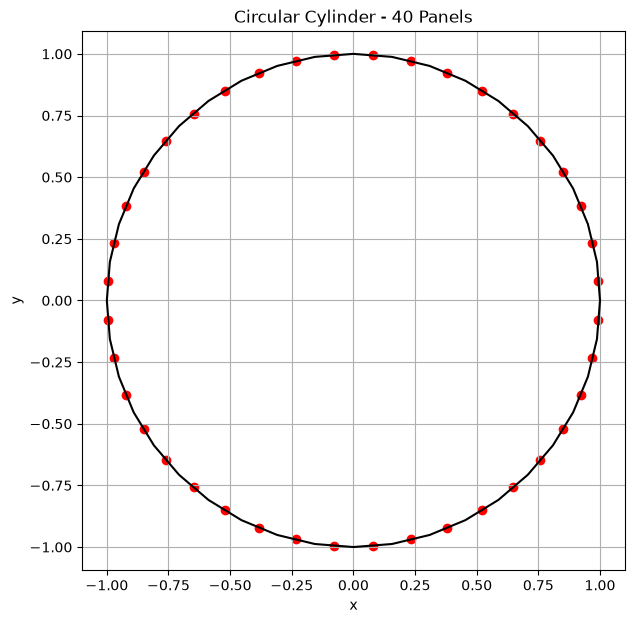

In [ ]:
# Figure 1 — Circular-cylinder geometry and panel discretisation.

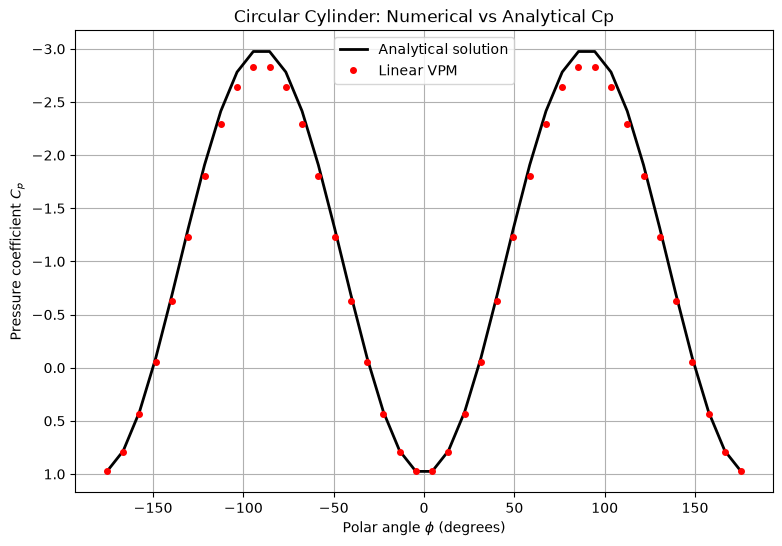

In [ ]:
# Figure 2 — Linear-strength numerical Cp compared with analytical cylinder Cp.

### 4.1 Linear-strength convergence

In [ ]:
# Saved linear-strength cylinder convergence table.

,Number of panels,RMS Cp error,Maximum Cp error,RMS normal residual
0,20,0.185898,0.296141,9.077813e-16
1,40,0.089058,0.144537,9.631350e-16
2,80,0.043505,0.070934,1.156301e-15
3,160,0.021490,0.035079,1.386613e-15
4,320,0.010679,0.017436,5.796120e-15


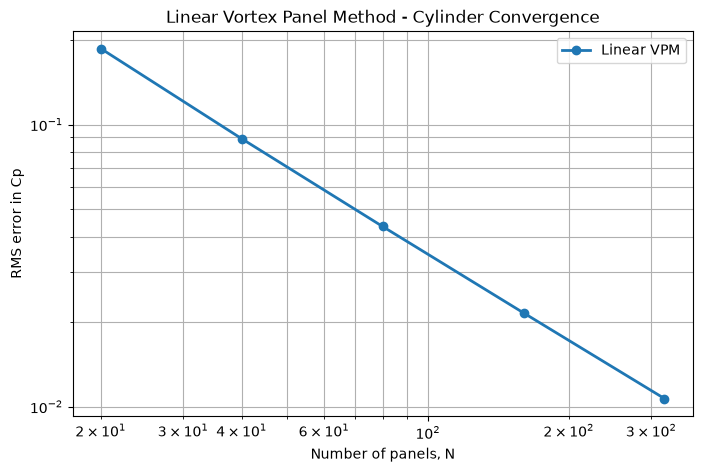

In [ ]:
# Figure 3 — Linear-strength cylinder RMS Cp error versus panel count.

The RMS pressure-coefficient error decreases from approximately 0.1859 at 20 panels to 0.01068 at 320 panels. Maximum error also decreases. Normal residuals are close to machine precision.

### 4.2 Constant-strength convergence

In [ ]:
# Saved constant-strength cylinder convergence table.

,Number of panels,RMS Cp error,Maximum Cp error,RMS normal residual,Circulation,Matrix rank
0,21,2.523571e-15,6.217249e-15,2.579107e-16,1.582068e-15,21
1,41,9.811906e-15,2.398082e-14,1.036876e-15,7.945034e-16,41
2,81,1.895655e-14,5.151435e-14,6.750798e-16,-1.112825e-15,81
3,161,8.403459e-14,2.047251e-13,7.800197e-16,8.881784e-16,161
4,321,1.273969e-13,3.126388e-13,1.013126e-15,-8.881784e-16,321


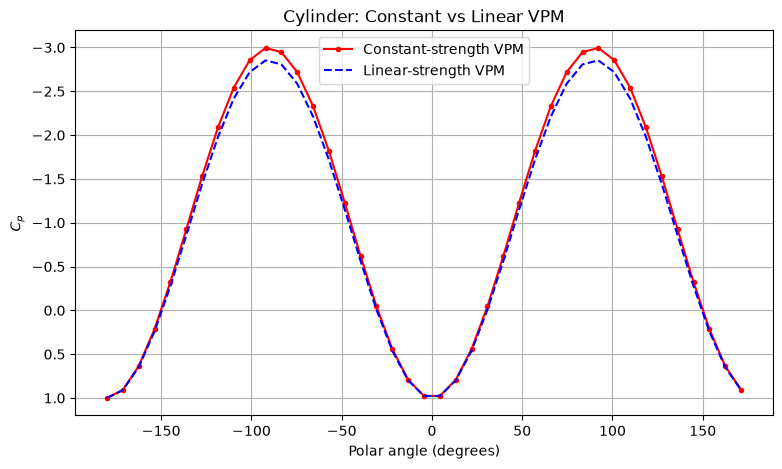

In [ ]:
# Figure 4 — Direct comparison of constant- and linear-strength cylinder Cp.

For the tested odd panel counts, constant-strength cylinder results reproduce analytical Cp to approximately machine precision. The computed circulation is close to zero. The direct comparison at 41 panels reports RMS difference approximately 0.08679. These observations apply to the cylinder implementation and should not automatically be generalised to airfoils.

## 5. Airfoil verification and convergence

Airfoils: symmetric NACA 0012 and cambered NACA 4412. Panel counts: 40, 80, 160, 320 and 640. The saved convergence calculations use α = 4°.

### 5.1 NACA 0012 — linear-strength VPM

In [ ]:
# Saved NACA 0012 linear-strength convergence table.

,Number of panels,CL,CD pressure,Normal RMS,Condition number
0,40,0.470687,0.010065,2.616939e-16,5526.141174
1,80,0.476789,0.004672,4.720975e-16,15461.166122
2,160,0.479749,0.002241,8.956335e-16,43596.811673
3,320,0.481201,0.001097,1.971634e-15,123211.925333
4,640,0.481919,0.000542,3.537644e-15,348431.697178


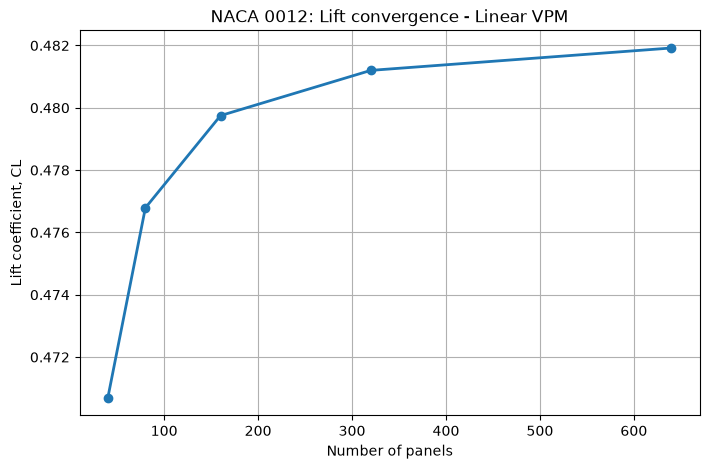

In [ ]:
# Figure 5 — NACA 0012 linear-strength CL convergence.

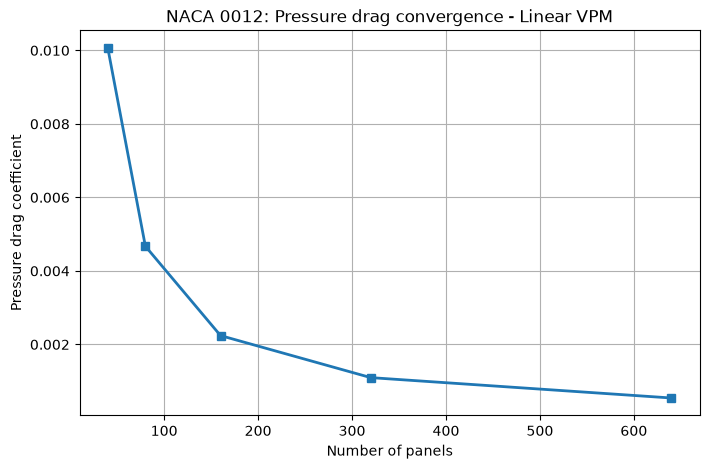

In [ ]:
# Figure 6 — NACA 0012 linear-strength pressure-drag convergence.

Lift coefficient increases from 0.470687 at 40 panels to 0.481919 at 640 panels, approaching approximately 0.482. Pressure drag decreases from 0.010065 to 0.000542. Normal residual remains close to machine precision.

### 5.2 NACA 0012 — constant-strength VPM

In [ ]:
# Saved NACA 0012 constant-strength convergence table.

,Number of panels,CL,CD pressure,Normal RMS,Condition number
0,40,0.480972,-0.000847,0.000125,1.215092e+04
1,80,0.482139,-0.000166,0.000047,1.575460e+05
2,160,0.482463,-0.000047,0.000036,4.377928e+05
3,320,0.482567,-0.000016,0.000020,1.221550e+06
4,640,0.482604,-0.000006,0.000010,3.427697e+06


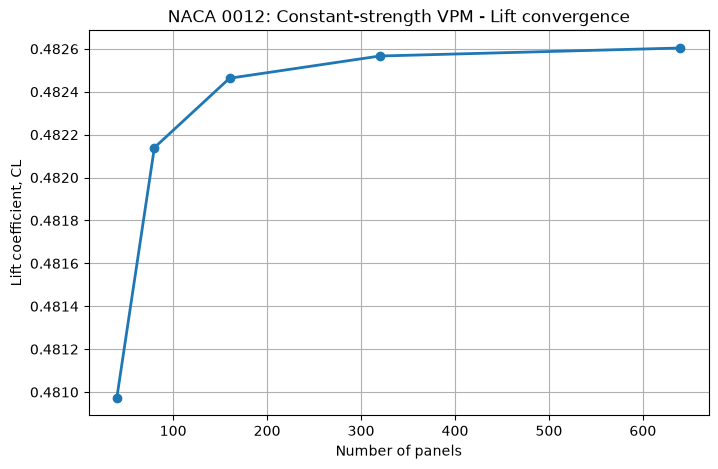

In [ ]:
# Figure 7 — NACA 0012 constant-strength CL convergence.

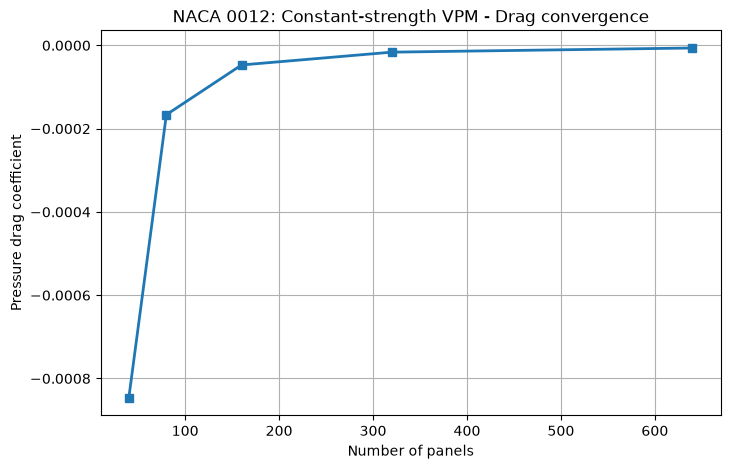

In [ ]:
# Figure 8 — NACA 0012 constant-strength pressure-drag convergence.

The saved constant-strength lift coefficient approaches approximately 0.4826. Slightly negative pressure-drag values approach zero with refinement and are numerical effects, not physical thrust. Normal residual is larger than for the linear method but decreases with panel refinement.

### 5.3 NACA 4412 — linear-strength VPM

In [ ]:
# Saved consolidated airfoil convergence table.

,Panels,NACA 0012 - Linear CL,NACA 0012 - Constant CL,NACA 4412 - Linear CL,NACA 4412 - Constant CL
0,40,0.470687,0.480972,0.503863,0.994074
1,80,0.476789,0.482139,0.511440,0.997851
2,160,0.479749,0.482463,0.514955,0.999033
3,320,0.481201,0.482567,0.516636,0.999453
4,640,0.481919,0.482604,0.517457,0.999619


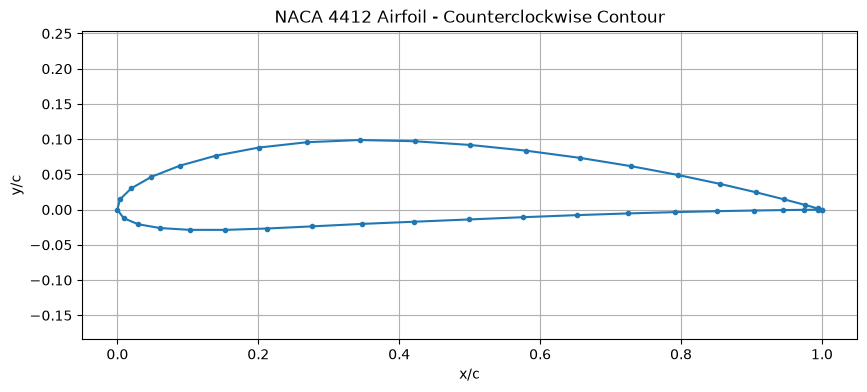

In [ ]:
# Figure 9 — NACA 4412 geometry and panel discretisation.

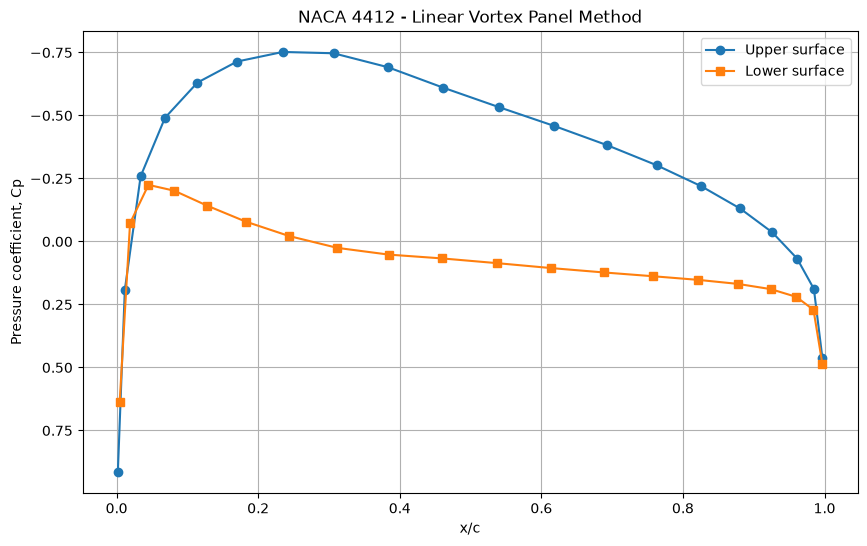

In [ ]:
# Figure 10 — NACA 4412 linear-strength Cp distribution.

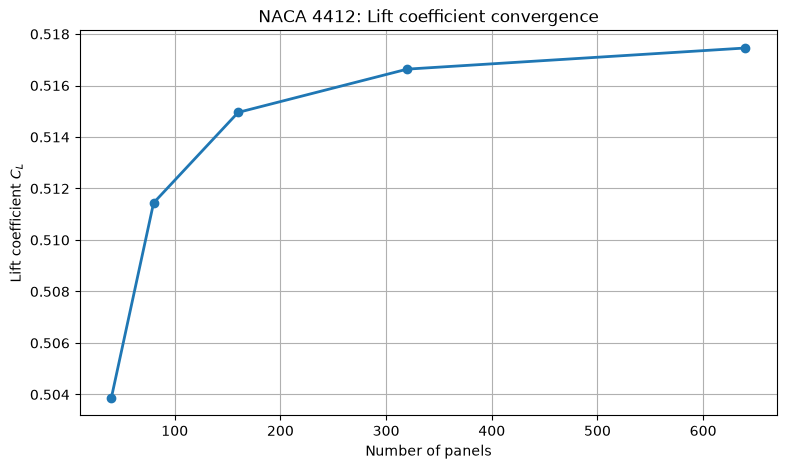

In [ ]:
# Figure 11 — NACA 4412 linear-strength CL convergence.

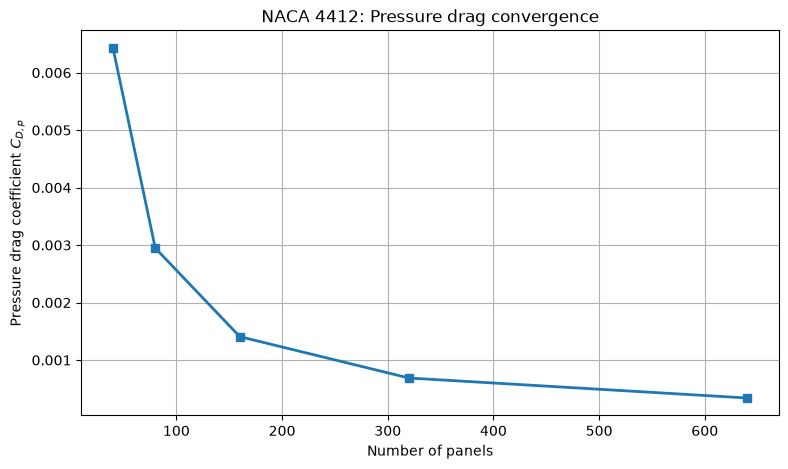

In [ ]:
# Figure 12 — NACA 4412 linear-strength pressure-drag convergence.

The saved NACA 4412 linear-strength convergence sequence gives CL = 0.503863, 0.511440, 0.514955, 0.516636 and 0.517457 for 40–640 panels. Pressure drag decreases from 0.006429 to 0.000340.

### 5.4 NACA 4412 — constant-strength VPM

In [ ]:
# Saved NACA 4412 constant-strength convergence table.

,Number of panels,CL,CD pressure,Normal RMS,Condition number
0,40,0.994074,-0.000540,0.000221,1.136163e+04
1,80,0.997851,-0.000039,0.000034,1.517320e+05
2,160,0.999033,0.000012,0.000003,4.389405e+05
3,320,0.999453,0.000012,0.000003,1.259716e+06
4,640,0.999619,0.000008,0.000002,3.502868e+06


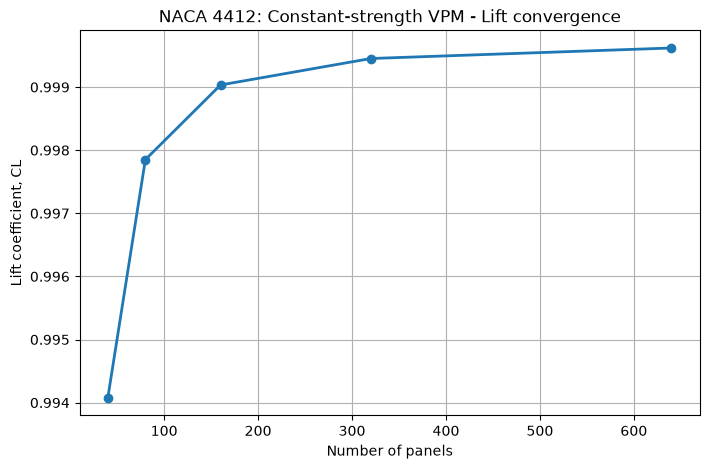

In [ ]:
# Figure 13 — NACA 4412 constant-strength CL convergence.

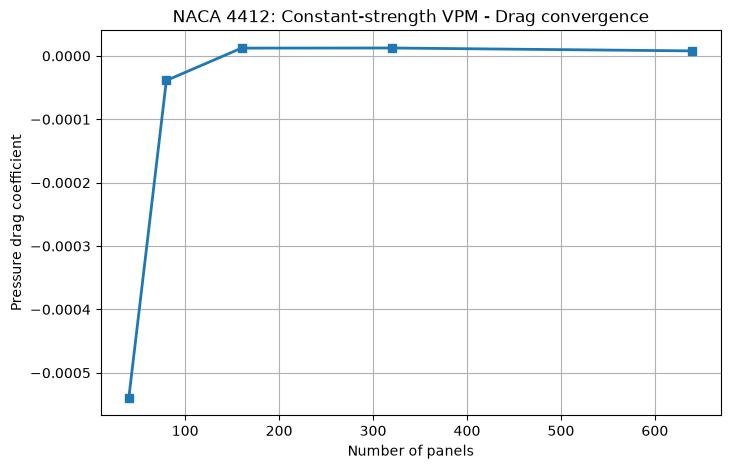

In [ ]:
# Figure 14 — NACA 4412 constant-strength pressure-drag convergence.

The saved constant-strength lift coefficient approaches approximately 1.000. Normal residual decreases to a few times 10⁻⁶ at finer panel counts. Matrix condition number increases substantially with panel count.

## 6. Airfoil characteristics and Cp distributions

The notebook plots pressure-coefficient distributions for both airfoils and both formulations. NACA 0012 is symmetric; NACA 4412 is cambered and produces positive lift at zero angle of attack in the saved calculations.

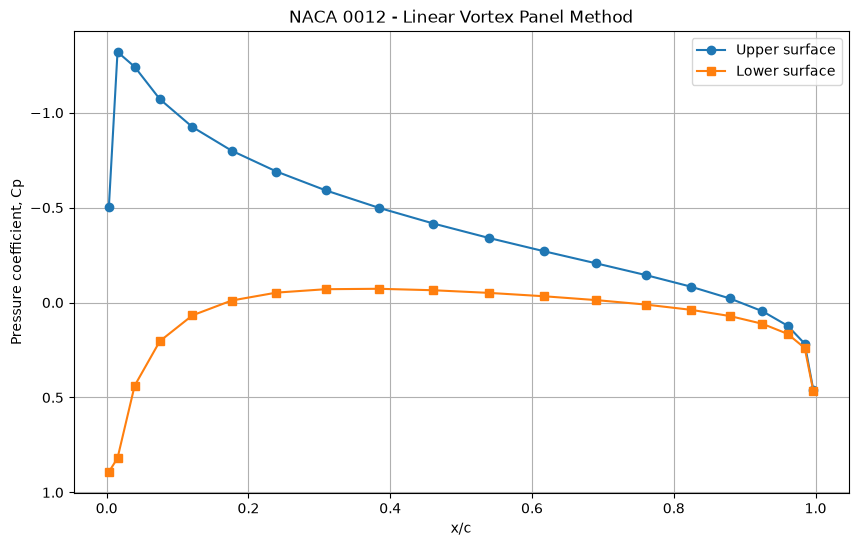

In [ ]:
# Figure 15 — NACA 0012 linear-strength Cp distribution.

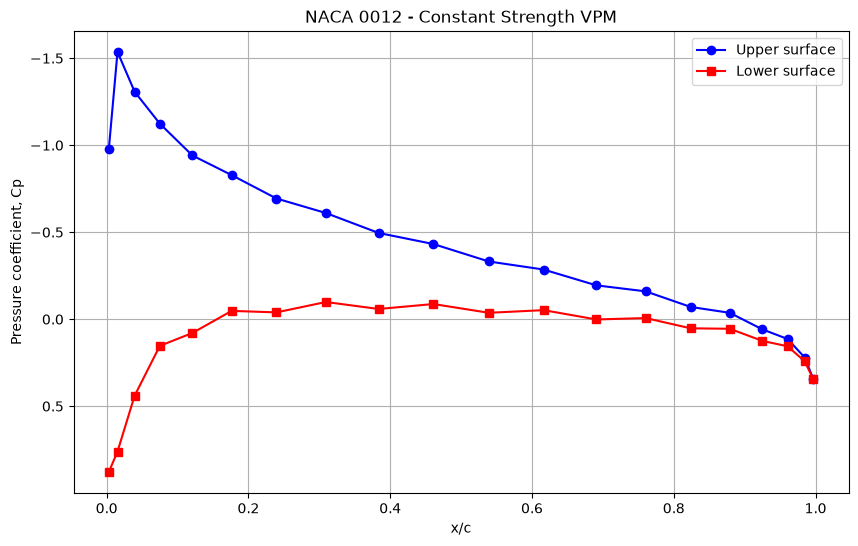

In [ ]:
# Figure 16 — NACA 0012 constant-strength Cp distribution.

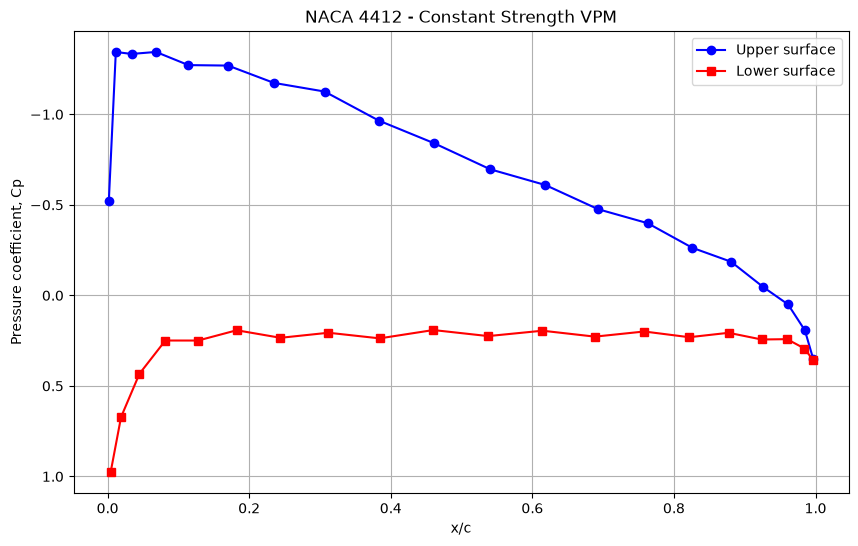

In [ ]:
# Figure 17 — NACA 4412 constant-strength Cp distribution.

### 6.1 Lift coefficient versus angle of attack

In [ ]:
# Saved lift coefficient versus angle-of-attack table.

,Alpha (deg),NACA 0012 - Constant,NACA 0012 - Linear,NACA 4412 - Constant,NACA 4412 - Linear
0,-6,-7.224734e-01,-7.142117e-01,-0.208434,-0.204852
1,-4,-4.821393e-01,-4.767885e-01,0.033559,0.033764
2,-2,-2.412169e-01,-2.385888e-01,0.275480,0.272656
3,0,9.107298e-17,7.320533e-16,0.517032,0.511440
4,2,2.412169e-01,2.385888e-01,0.757921,0.749727
5,4,4.821393e-01,4.767885e-01,0.997851,0.987129
6,6,7.224734e-01,7.142117e-01,1.236530,1.223258
7,8,9.619256e-01,9.504739e-01,1.473668,1.457727
8,10,1.200204e+00,1.185195e+00,1.708976,1.690155
9,12,1.437018e+00,1.418002e+00,1.942169,1.920166


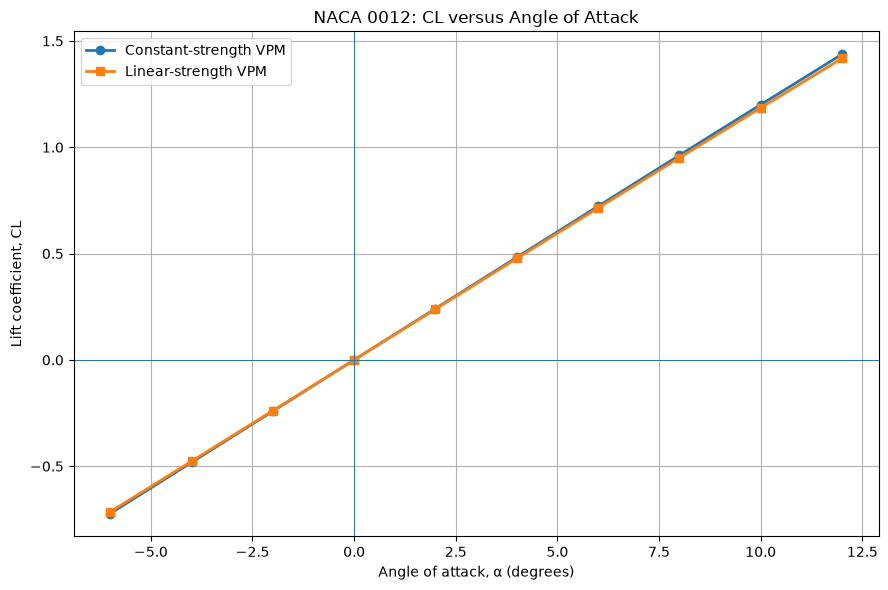

In [ ]:
# Figure 18 — NACA 0012 CL versus angle of attack.

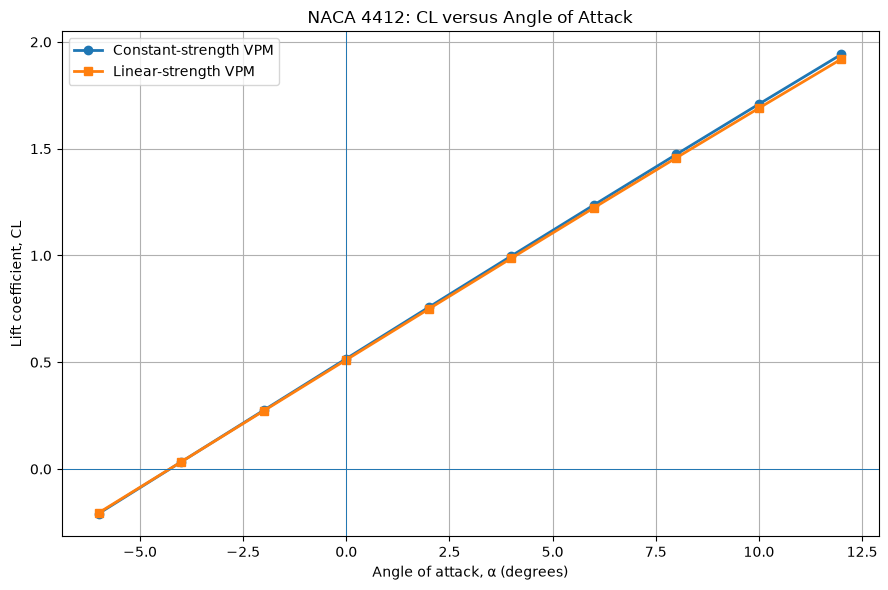

In [ ]:
# Figure 19 — NACA 4412 CL versus angle of attack.

For NACA 0012, the saved curves are approximately linear and pass near zero lift at zero incidence. For NACA 4412, the curves are shifted upward, consistent with camber and positive lift at zero incidence.

**Consistency check required:** the NACA 4412 linear-strength convergence table reports CL = 0.511440 at 80 panels and 4°, while the saved angle-of-attack plot/table reports approximately CL = 0.98713 at 4°. These are not consistent. Geometry generation, panel definition, force integration and the data used in the plot must be checked and rerun before final submission.

## 7. Panel spacing and thickness studies

### 7.1 Uniform versus cosine panel spacing

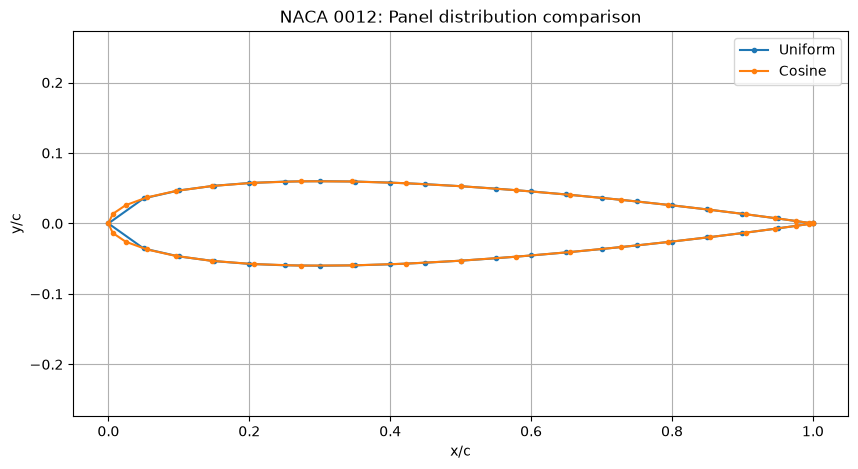

In [ ]:
# Figure 20 — NACA 0012 uniform and cosine panel spacing.

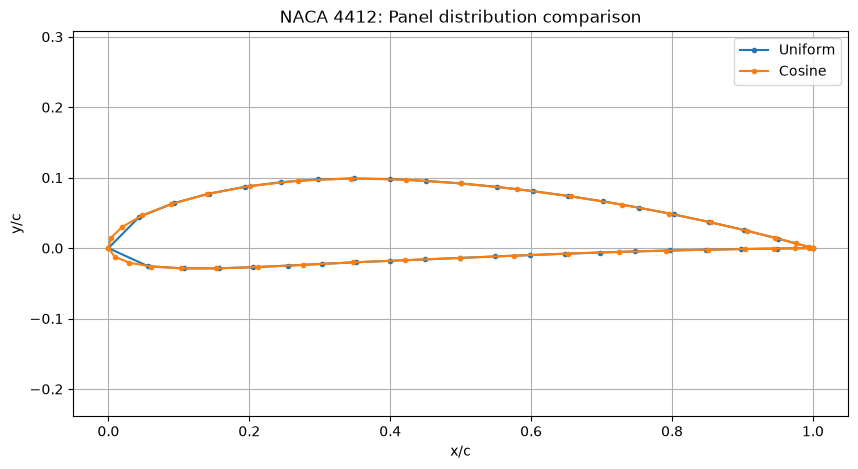

In [ ]:
# Figure 21 — NACA 4412 uniform and cosine panel spacing.

In [ ]:
# Saved uniform-versus-cosine panel distribution results.

,Airfoil,Spacing,Method,CL,CDp,Normal RMS,Condition number
0,0012,uniform,Constant,0.484249,-0.004781,1.483340e-03,5797.672889
1,0012,uniform,Linear,0.473563,0.010074,4.086877e-16,1154.490011
2,0012,cosine,Constant,0.482463,-0.000047,3.591081e-05,437792.824351
3,0012,cosine,Linear,0.479749,0.002241,8.956335e-16,43596.811673
4,4412,uniform,Constant,0.998799,-0.004978,1.361171e-03,5732.237752
5,4412,uniform,Linear,0.986752,0.009436,5.591837e-16,1165.317388
6,4412,cosine,Constant,0.999033,0.000012,2.886210e-06,438940.498734
7,4412,cosine,Linear,0.993579,0.002243,9.701549e-16,43977.088396


The saved table shows that panel spacing changes the predicted force coefficients. Cosine spacing gives smaller constant-strength normal residuals than uniform spacing in the tested cases. Linear-strength normal residuals remain close to machine precision for both distributions.

### 7.2 Airfoil thickness study

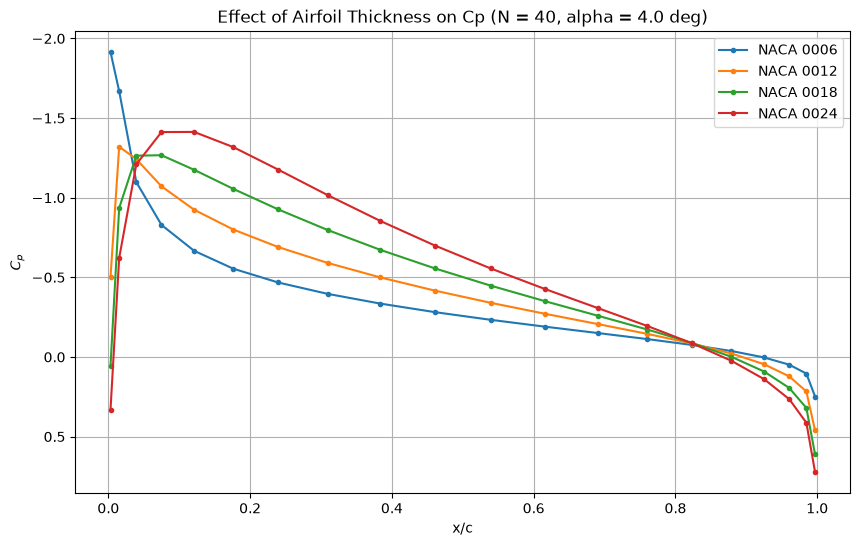

In [ ]:
# Figure 22 — Cp distributions for 6%, 12%, 18% and 24% thickness.

In [ ]:
# Saved RMS Cp-difference versus thickness table.

,Thickness (%),RMS Cp difference
0,6.0,0.154753
1,12.0,0.117897
2,18.0,0.088661
3,24.0,0.076063


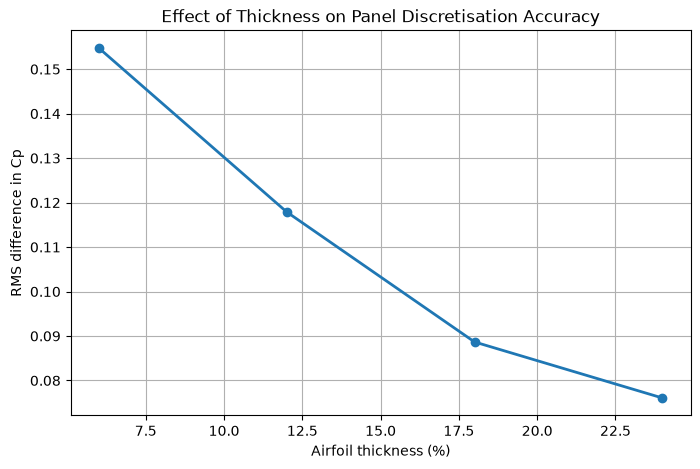

In [ ]:
# Figure 23 — RMS Cp-difference metric versus thickness.

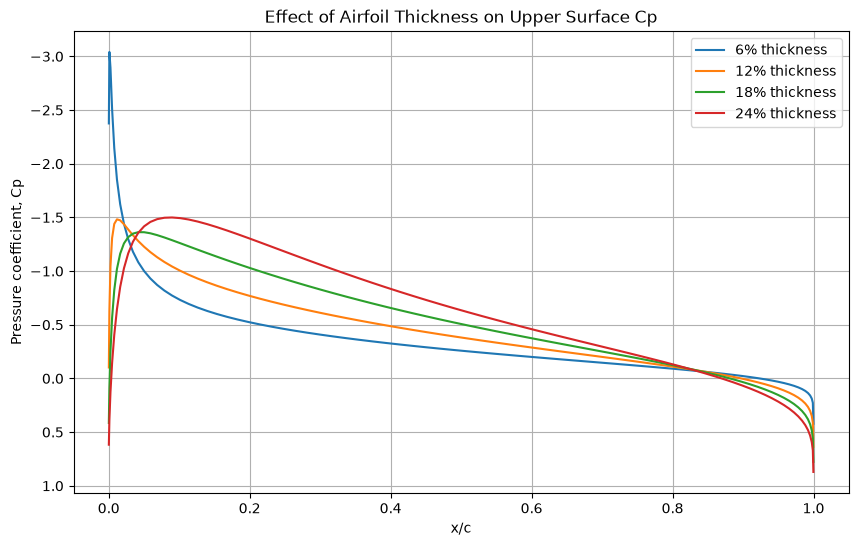

In [ ]:
# Figure 24 — Upper-surface Cp comparison for different thicknesses.

The saved RMS Cp-difference decreases from approximately 0.154753 at 6% thickness to 0.076063 at 24% thickness.

**Important:** this trend does not demonstrate that predictive capability decreases as thickness increases. A reference-based validation study and clearly defined error measure are needed before claiming that the assignment requirement has been demonstrated.

## 8. Problems encountered and corrections made

### 8.1 Constant-strength airfoil system
The earlier system used N-1 normal-flow equations and replaced the remaining equation with the Kutta condition, producing an N× N system. It gave unstable lift trends in some airfoil calculations. The revised assembly retains all N normal-flow equations and appends the Kutta equation, producing an (N+1)× N rectangular system.

### 8.2 Rectangular matrix passed to `numpy.linalg.solve`
A later analysis cell still called `np.linalg.solve(M, b)`. NumPy raised `LinAlgError` because the matrix was not square. Constant-strength calls were changed to `solve_constant_airfoil_system(M, b, rcond=1e-3)`.

### 8.3 Wrong solver used in linear-strength method
The constant-strength SVD solver was accidentally inserted into `vortex_panel_method_1()`, causing a dimension mismatch. The linear wrapper was restored to `solve_vortex_strengths(M, b)`. Only `vortex_panel_method_0()` uses the constant-strength SVD solver.

### 8.4 NACA 4412 inconsistency
The saved NACA 4412 linear-strength panel-count study and angle-of-attack study disagree at the same nominal condition. This remains unresolved and is explicitly flagged.

### 8.5 Thickness requirement not demonstrated
The current RMS Cp-difference metric decreases with thickness. It does not support the assignment's requested trend. A consistent reference solution and error metric are required.

### 8.6 Numerical conditioning and pressure drag
The constant-strength matrix condition number increases substantially with panel count. Some constant-strength pressure-drag values are slightly negative but approach zero; these are numerical effects, not physical negative drag.


## 9. Conclusions and limitations

Both VPM formulations were implemented and tested. Cylinder and airfoil results, convergence trends and unresolved issues are summarised in Section 11. The model is inviscid and incompressible; it excludes skin friction, boundary-layer transition, viscous separation, stall and shock waves. The calculated pressure drag is not total drag.

## 10. References and acknowledgement

1. Anderson, J. D. (2017). *Fundamentals of Aerodynamics* (6th ed.). McGraw-Hill.
2. Katz, J., & Plotkin, A. (2001). *Low-Speed Aerodynamics* (2nd ed.). Cambridge University Press.

**AI acknowledgement:** ChatGPT assisted with code organisation, debugging, result interpretation and report preparation. The student is responsible for verifying and understanding the submitted work.

## 11. Results and discussion

### 11.1 Circular-cylinder verification

**Linear-strength VPM**

| Panels, N | RMS Cₚ error | Maximum Cₚ error | RMS normal residual |
|---:|---:|---:|---:|
| 20 | 0.185898 | 0.296141 | 9.08×10⁻¹⁶ |
| 40 | 0.089058 | 0.144537 | 9.63×10⁻¹⁶ |
| 80 | 0.043505 | 0.070934 | 1.16×10⁻¹⁵ |
| 160 | 0.021490 | 0.035079 | 1.39×10⁻¹⁵ |
| 320 | 0.010679 | 0.017436 | 5.80×10⁻¹⁵ |

The RMS error decreases by about 94% from 20 to 320 panels. The normal residual stays near machine precision. Thus the boundary condition is solved accurately and the pressure solution converges as the panel count increases.

**Constant-strength VPM**

| Panels, N | RMS Cₚ error | Maximum error | Circulation |
|---:|---:|---:|---:|
| 21 | 2.52×10⁻¹⁵ | 6.22×10⁻¹⁵ | 1.58×10⁻¹⁵ |
| 41 | 9.81×10⁻¹⁵ | 2.40×10⁻¹⁴ | 7.95×10⁻¹⁶ |
| 81 | 1.90×10⁻¹⁴ | 5.15×10⁻¹⁴ | -1.11×10⁻¹⁵ |
| 161 | 8.40×10⁻¹⁴ | 2.05×10⁻¹³ | 8.88×10⁻¹⁶ |
| 321 | 1.27×10⁻¹³ | 3.13×10⁻¹³ | -8.88×10⁻¹⁶ |

For these cylinder cases, the constant-strength results match the analytical Cₚ to round-off level and circulation is essentially zero. This is the result of this particular implementation and test; it should not be generalized to every geometry.

### 11.2 Airfoil panel-count convergence at α=4°

**NACA 0012**

| N | Linear Cₗ | Linear Cᴅₚ | Constant Cₗ | Constant Cᴅₚ |
|---:|---:|---:|---:|---:|
| 40 | 0.470687 | 0.010065 | 0.480972 | -0.000847 |
| 80 | 0.476789 | 0.004672 | 0.482139 | -0.000166 |
| 160 | 0.479749 | 0.002241 | 0.482463 | -0.000047 |
| 320 | 0.481201 | 0.001097 | 0.482567 | -0.000016 |
| 640 | 0.481919 | 0.000542 | 0.482604 | -0.000006 |

Both methods approach Cₗ≈0.482. Linear-method Cᴅₚ decreases towards zero. The small negative constant-method values also approach zero and are numerical integration errors, not physical negative drag.

**NACA 4412**

| N | Linear Cₗ | Linear Cᴅₚ | Constant Cₗ | Constant Cᴅₚ |
|---:|---:|---:|---:|---:|
| 40 | 0.503863 | 0.006429 | 0.994074 | -0.000540 |
| 80 | 0.511440 | 0.002948 | 0.997851 | -0.000039 |
| 160 | 0.514955 | 0.001407 | 0.999033 | 0.000012 |
| 320 | 0.516636 | 0.000688 | 0.999453 | 0.000012 |
| 640 | 0.517457 | 0.000340 | 0.999619 | 0.000008 |

The linear-strength sequence approaches Cₗ≈0.5175, while the constant-strength sequence approaches Cₗ≈1.000. These two limits differ substantially. The NACA 4412 results therefore require a formulation/implementation check before interpreting the difference as a physical effect.

### 11.3 Lift versus angle of attack

| α (deg) | 0012 constant | 0012 linear | 4412 constant | 4412 linear |
|---:|---:|---:|---:|---:|
| -6 | -0.722473 | -0.714212 | -0.208434 | -0.204852 |
| -4 | -0.482139 | -0.476789 | 0.033559 | 0.033764 |
| -2 | -0.241217 | -0.238589 | 0.275480 | 0.272656 |
| 0 | 0.000000 | 0.000000 | 0.517032 | 0.511440 |
| 2 | 0.241217 | 0.238589 | 0.757921 | 0.749727 |
| 4 | 0.482139 | 0.476789 | 0.997851 | 0.987129 |
| 6 | 0.722473 | 0.714212 | 1.236530 | 1.223258 |
| 8 | 0.961926 | 0.950474 | 1.473668 | 1.457727 |
| 10 | 1.200204 | 1.185195 | 1.708976 | 1.690155 |
| 12 | 1.437018 | 1.418002 | 1.942169 | 1.920166 |

NACA 0012 is symmetric: the calculated lift is approximately zero at zero incidence and increases nearly linearly with α. NACA 4412 is cambered and gives positive lift at zero incidence. **The NACA 4412 linear-strength values in this table do not agree with its panel-count convergence table** (at 4°, 0.987129 versus 0.511440 at 80 panels). This discrepancy remains unresolved and the Cₗ(α) curve should be treated as provisional.

### 11.4 Uniform and cosine panel spacing

| Airfoil | Spacing | Method | Cₗ | Cᴅₚ | Normal RMS |
|---|---|---|---:|---:|---:|
| 0012 | Uniform | Constant | 0.484249 | -0.004781 | 1.48×10⁻³ |
| 0012 | Cosine | Constant | 0.482463 | -0.000047 | 3.59×10⁻⁵ |
| 0012 | Uniform | Linear | 0.473563 | 0.010074 | 4.09×10⁻¹⁶ |
| 0012 | Cosine | Linear | 0.479749 | 0.002241 | 8.96×10⁻¹⁶ |
| 4412 | Uniform | Constant | 0.998799 | -0.004978 | 1.36×10⁻³ |
| 4412 | Cosine | Constant | 0.999033 | 0.000012 | 2.89×10⁻⁶ |
| 4412 | Uniform | Linear | 0.986752 | 0.009436 | 5.59×10⁻¹⁶ |
| 4412 | Cosine | Linear | 0.993579 | 0.002243 | 9.70×10⁻¹⁶ |

Cosine spacing reduces the constant-strength normal residual in both airfoil cases. It also changes the calculated force coefficients. The linear-strength normal residual is close to machine precision for both distributions; this residual alone does not establish which force prediction is more accurate.

### 11.5 Thickness study

| Airfoil | Thickness | Cₗ | Cᴅₚ | Maximum |Cₚ| |
|---|---:|---:|---:|---:|
| NACA 0006 | 6% | 0.457874 | 0.002438 | 3.041072 |
| NACA 0012 | 12% | 0.479749 | 0.002241 | 1.481841 |
| NACA 0018 | 18% | 0.501788 | 0.002628 | 1.362380 |
| NACA 0024 | 24% | 0.524031 | 0.003169 | 1.499216 |

The reported RMS Cₚ-difference metric decreases from 0.154753 at 6% thickness to 0.076063 at 24%. Therefore, these calculations do **not** demonstrate the assignment's requested reduction in predictive capability with increasing thickness. This metric compares pressure distributions; it is not an error against experimental or validated reference data.

### 11.6 Overall findings

- Cylinder: linear-strength Cₚ error decreases consistently with refinement; constant-strength cylinder error is at round-off level for the tested odd panel counts.
- NACA 0012: both formulations approach Cₗ≈0.482 at 4°.
- NACA 4412: constant- and linear-strength convergence values differ significantly, and the linear Cₗ(α) result is inconsistent with its panel-count study.
- Panel distribution: cosine spacing reduces the constant-strength normal residual in the tested cases.
- Thickness: the current metric does not verify the requested loss of predictive capability.

The method is inviscid and incompressible. It does not predict skin-friction drag, boundary-layer transition, viscous separation, stall or shock waves. Pressure drag calculated here is not total drag.


## Appendix A. Complete executable Python implementation and plotting code

The following code is taken from the latest uploaded **`Linear_VPM(20261122-075337).ipynb`** implementation notebook. It includes the setup, geometry and influence functions, both VPM formulations, cylinder and airfoil calculations, convergence studies, and the actual `matplotlib` plotting commands used to generate the figures in this report.

The earlier report displayed saved plot outputs in cells that contained only figure labels. This appendix supplies the corresponding editable Python source so the plotting procedure is visible to the examiner.

**Execution:** Run this cell from top to bottom. It recomputes the numerical cases and generates the plots. It is intentionally kept as one source cell to preserve the execution order and dependencies from the original implementation notebook. The figures already shown in the report are the saved results; running this cell regenerates them.


In [ ]:
# PRELIMINARY SETUP AND SHARED FUNCTIONS

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display


# 01 | NACA 0012 geometry and initial panel visualisation

import numpy as np
import matplotlib.pyplot as plt

# NACA 0012 geometry
c = 1.0                 
t = 0.12                
n = 20                  

# Cosine spacing
beta = np.linspace(0.0, np.pi, n + 1)
x_dist = 0.5 * c * (1.0 - np.cos(beta))


yt = 5.0 * t * c * (
    0.2969 * np.sqrt(x_dist / c)
    - 0.1260 * (x_dist / c)
    - 0.3516 * (x_dist / c)**2
    + 0.2843 * (x_dist / c)**3
    - 0.1036 * (x_dist / c)**4)
yt[-1] = 0.0

# Upper and lower surface coordinates
x_upper = x_dist
y_upper = yt

x_lower = x_dist
y_lower = -yt

# Arrange contour counterclockwise:
x = np.concatenate((x_upper[::-1], x_lower[1:]))    # Stores them as a single long array in counterclockwise direction
y = np.concatenate((y_upper[::-1], y_lower[1:]))

# Plot the airfoil
plt.figure(figsize=(10, 4))
plt.plot(x, y, 'o-', markersize=3)
plt.xlabel("x / c")
plt.ylabel("y / c")
plt.title("NACA 0012 Airfoil - Counterclockwise Contour")
plt.axis("equal")
plt.grid(True)
plt.show()

print("Number of surface nodes:", len(x))
print("Number of panels:", len(x) - 1)
print("\nx_coordinates of panels", x)
print("\ny_coordinates of panels", y)
print("-" * 100)





        ################################################################################################################################


# 02 | Panel geometry function

# DEFINING GEOMETRY FOR THE VORTEX PANELS

def define_panels(x, y):

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if x.ndim != 1 or y.ndim != 1:
        raise ValueError("x and y must be one-dimensional arrays.")

    if len(x) != len(y):
        raise ValueError("x and y must have the same length.")

    if len(x) < 4:
        raise ValueError("At least three panels are required for a closed contour.")

    if not np.all(np.isfinite(x)) or not np.all(np.isfinite(y)):
        raise ValueError("Coordinates must contain only finite values.")

    
    dx = np.diff(x)   # Has the output in an array
    dy = np.diff(y)
    
    length = np.hypot(dx, dy)   # Calculate individual panel lengths and put it in an array 
    if np.any(length <= 0.0):
        raise ValueError("There is an error in the panel calculation")

    
    theta = np.arctan2(dy, dx)   # Panel tangent angles in global coordinates
    theta_degrees = np.rad2deg(np.arctan2(dy, dx))    # arctan2() places the angle in the correct quadrant across the full circle
    
    
    x_control = 0.5 * (x[:-1] + x[1:])  # are the midpoints of the panel
    y_control = 0.5 * (y[:-1] + y[1:])

    
    tangent = np.column_stack((np.cos(theta),np.sin(theta)))   # Unit tangent vectors
    normal = np.column_stack((np.sin(theta),-np.cos(theta)))   # Outward unit normals
                                                               # for counterclockwise contour
    
   
    signed_area = 0.5 * np.sum(x[:-1] * y[1:] - x[1:] * y[:-1])  # Signed polygon area check - Shoelace formula

    if signed_area <= 0.0:
        raise ValueError("The contour must be ordered counterclockwise.")


    return {
        "x": x,
        "y": y,
        "length": length,
        "theta": theta,
        "x_control": x_control,
        "y_control": y_control,
        "tangent": tangent,
        "normal": normal,
        "signed_area": signed_area,
        "num_panels": len(length),
    }                                           # Storing them as dictionary

    
      
      ########################################################################################################################################


def calculate_influence_integrals(panels):

    x = panels["x"]
    y = panels["y"]
    x_control = panels["x_control"]
    y_control = panels["y_control"]
    S = panels["length"]
    theta = panels["theta"]
    N = panels["num_panels"]

    I0_matrix = np.zeros((N, N))
    J0_matrix = np.zeros((N, N))
    I1_matrix = np.zeros((N, N))
    J1_matrix = np.zeros((N, N))

    # Loop over observation points
    for i in range(N):

        xc = x_control[i]
        yc = y_control[i]

        for j in range(N):

            Sj = S[j]
            theta_j = theta[j]

            dx = xc - x[j]    # Global coordinate differences
            dy = yc - y[j]

            x_local = dx*np.cos(theta_j) + dy*np.sin(theta_j)    # Global coordinate differences 
            y_local = -dx*np.sin(theta_j) + dy*np.cos(theta_j)

            if i == j:

                I0_matrix[i, j] = -np.pi
                J0_matrix[i, j] = 0.0
                I1_matrix[i, j] = -np.pi * Sj / 2.0
                J1_matrix[i, j] = -Sj
                
            else:
                
                I0 = np.arctan2(y_local, x_local-Sj) - np.arctan2(y_local, x_local)
                                                                  
                numerator = x_local**2 + y_local**2
                denominator = (x_local-Sj)**2 + y_local**2
                J0 = 0.5*np.log(numerator/denominator)

                I1 = x_local*I0 - y_local*J0

                J1 = x_local*J0 - Sj + y_local*I0

                
                I0_matrix[i, j] = I0
                J0_matrix[i, j] = J0
                I1_matrix[i, j] = I1
                J1_matrix[i, j] = J1

    return I0_matrix, J0_matrix, I1_matrix, J1_matrix

def calculate_influence_integralss(x, y, S):      # Redifining the function for code clarity
                                                  # Calculating only the off-diagolnal terms(1560 terms)
    I0 = np.arctan2(S * y, x * (x - S) + y**2)

    numerator = x**2 + y**2
    denominator = (x - S)**2 + y**2
    J0 = 0.5 * np.log(numerator / denominator)

    I1 = x * I0 - y * J0

    J1 = x * J0 - S + y * I0

    return I0, J0, I1, J1

def calculate_velocity_coefficients(panels):

    N = panels["num_panels"]
    x = panels["x"]
    y = panels["y"]
    xc = panels["x_control"]
    yc = panels["y_control"]
    length = panels["length"]
    theta = panels["theta"]

    # Matrices for normal and tangential influences
    A_normal = np.zeros((N, N + 1))
    T_tangent = np.zeros((N, N + 1))

    for i in range(N):

        # Observation point i
        for j in range(N):

            S = length[j]
            theta_j = theta[j]

            dx = xc[i] - x[j]
            dy = yc[i] - y[j]
            
            x_local = dx * np.cos(theta_j) + dy * np.sin(theta_j)    # Transform into source panel local coordinates
            y_local = -dx * np.sin(theta_j) + dy * np.cos(theta_j)

            # Self-influence coefficients
            if i == j:

                U_L = 1.0 / 4.0
                U_R = 1.0 / 4.0
                W_L = 1.0 / (2.0 * np.pi)
                W_R = -1.0 / (2.0 * np.pi)

            else:
                
                I0, J0, I1, J1 = calculate_influence_integralss(x_local, y_local, S)

                U_L = -(I0 - I1 / S) / (2.0 * np.pi)     # Local tangential velocity coefficients
                U_R = -I1 / (2.0 * np.pi * S)

                W_L = (J0 - J1 / S) / (2.0 * np.pi)      # Local normal velocity coefficients
                W_R = J1 / (2.0 * np.pi * S)
            
            delta = theta[i] - theta[j]     # Relative panel orientation(local and global)

            
            A_L = U_L * np.sin(delta) - W_L * np.cos(delta)    # Normal influence coefficients
            A_R = U_R * np.sin(delta) - W_R * np.cos(delta)

            
            T_L = U_L * np.cos(delta) + W_L * np.sin(delta)     # Tangential influence coefficients
            T_R = U_R * np.cos(delta) + W_R * np.sin(delta)

            
            A_normal[i, j] += A_L         # Store contributions at the two source-panel endpoints
            A_normal[i, j + 1] += A_R

            T_tangent[i, j] += T_L
            T_tangent[i, j + 1] += T_R

    return A_normal, T_tangent

def assemble_linear_system(panels, A_normal, V_inf, alpha):

    N = panels["num_panels"]
    theta = panels["theta"]

    M = np.zeros((N + 1, N + 1))
    
    M[:N, :] = A_normal     # First N rows: no-penetration boundary condition
    
    M[N, 0] = 1.0      # Last row: Kutta condition
    M[N, N] = 1.0
    
    b = np.zeros(N + 1)    # RHS vector
    b[:N] = -V_inf * np.sin(theta - alpha)

    b[N] = 0.0       # Last RHS entry is zero for the Kutta condition

    return M, b

def solve_vortex_strengths(M, b):
    
    strength = np.linalg.solve(M, b)
    return strength

def tangential_velocity_and_cp(panels, T_tangent, strength, V_inf, alpha):

    N = panels["num_panels"]
    theta = panels["theta"]

    V_t_freestream = V_inf * np.cos(alpha - theta)
    V_t_ind = T_tangent @ strength

    V_t = V_t_freestream + V_t_ind
    
    Cp = 1.0 - (V_t / V_inf)**2

    return V_t, Cp

def calculate_constant_velocity_coefficients(panels):

    N = panels["num_panels"]
    x = panels["x"]
    y = panels["y"]
    xc = panels["x_control"]
    yc = panels["y_control"]
    S = panels["length"]
    theta = panels["theta"]

    A_normal = np.zeros((N, N))
    T_tangent = np.zeros((N, N))

    for i in range(N):
        
        for j in range(N):

            if i == j:
                U = 0.5
                W = 0.0

            else:
                dx = xc[i] - x[j]
                dy = yc[i] - y[j]

                x_local = (dx * np.cos(theta[j])+ dy * np.sin(theta[j]))
                y_local = (-dx * np.sin(theta[j])+ dy * np.cos(theta[j]))
                
                Sj = S[j]

                I0 = np.arctan2(Sj * y_local,x_local * (x_local - Sj) + y_local**2)
                J0 = 0.5 * np.log((x_local**2 + y_local**2)/((x_local - Sj)**2 + y_local**2))

                U = -I0 / (2.0 * np.pi)
                W = J0 / (2.0 * np.pi)

            delta_theta = theta[i] - theta[j]
            
            A_normal[i, j] = (U * np.sin(delta_theta)- W * np.cos(delta_theta))
            T_tangent[i, j] = (U * np.cos(delta_theta)+ W * np.sin(delta_theta))

    return A_normal, T_tangent


def assemble_constant_airfoil_system(panels, A_normal, V_inf, alpha):

    N = panels["num_panels"]
    theta = panels["theta"]

    M = np.zeros((N + 1, N))     # All N no-penetration equations
    M[:N, :] = A_normal

    M[N, 0] = 1.0      # Additional Kutta-condition equation
    M[N, -1] = 1.0

    b = np.zeros(N + 1)     # Freestream contribution
    b[:N] = -V_inf * np.sin(theta - alpha)

    return M, b


def solve_constant_airfoil_system(M, b, rcond=1e-3):

    U, singular_values, Vh = np.linalg.svd(M, full_matrices=False)

    # Retain only sufficiently large singular values
    keep = singular_values > rcond * singular_values[0]

    # Truncated SVD solution
    gamma = Vh[keep, :].T @ ((U[:, keep].T @ b) / singular_values[keep])

    return gamma


def generate_naca_4412(n_half=20):

    # NACA 4412 
    m = 0.04       
    p = 0.40      
    t = 0.12      

    # Cosine spacing
    beta = np.linspace(0.0, np.pi, n_half + 1)
    x = 0.5 * (1.0 - np.cos(beta))

    # Thickness distribution
    yt = 5.0 * t * (0.2969 * np.sqrt(x)- 0.1260 * x- 0.3516 * x**2+ 0.2843 * x**3- 0.1036 * x**4)

    # Camber line and its slope
    yc = np.zeros_like(x)
    dyc_dx = np.zeros_like(x)

    for i in range(len(x)):

        if x[i] <= p:
            yc[i] = (m / p**2) * (2.0 * p * x[i] - x[i]**2)

            dyc_dx[i] = (2.0 * m / p**2) * (p - x[i])

        else:
            yc[i] = (m / (1.0 - p)**2) * ((1.0 - 2.0 * p)+ 2.0 * p * x[i] - x[i]**2)

            dyc_dx[i] = (2.0 * m / (1.0 - p)**2) * (p - x[i])

    # Camber-line angle
    theta_c = np.arctan(dyc_dx)

    # Upper and lower surface coordinates
    xu = x - yt * np.sin(theta_c)
    yu = yc + yt * np.cos(theta_c)

    xl = x + yt * np.sin(theta_c)
    yl = yc - yt * np.cos(theta_c)

    yu[-1] = 0.0
    yl[-1] = 0.0

    # Counterclockwise ordering:
    x_nodes = np.concatenate((xu[::-1], xl[1:]))
    y_nodes = np.concatenate((yu[::-1], yl[1:]))

    return x_nodes, y_nodes

def generate_naca_0012(n_half=20):

    c = 1.0
    t = 0.12

    # Cosine spacing
    beta = np.linspace(0.0, np.pi, n_half + 1)
    x_dist = 0.5 * c * (1.0 - np.cos(beta))

    # NACA 0012 thickness distribution
    yt = 5.0 * t * c * (
        0.2969 * np.sqrt(x_dist / c)
        - 0.1260 * (x_dist / c)
        - 0.3516 * (x_dist / c)**2
        + 0.2843 * (x_dist / c)**3
        - 0.1036 * (x_dist / c)**4
    )

    # Closed trailing edge
    yt[-1] = 0.0

    # Upper and lower surfaces
    x_upper = x_dist
    y_upper = yt

    x_lower = x_dist
    y_lower = -yt

    # Counterclockwise contour
    x_nodes = np.concatenate((x_upper[::-1], x_lower[1:]))
    y_nodes = np.concatenate((y_upper[::-1], y_lower[1:]))

    return x_nodes, y_nodes

def generate_naca00xx(t_ratio, n_half):

    beta = np.linspace(0.0, np.pi, n_half + 1)
    x = 0.5 * (1.0 - np.cos(beta))

    yt = 5.0 * t_ratio * (0.2969 * np.sqrt(x)- 0.1260 * x- 0.3516 * x**2+ 0.2843 * x**3- 0.1036 * x**4)
    yt[-1] = 0.0

    x_nodes = np.concatenate((x[::-1], x[1:]))
    y_nodes = np.concatenate((yt[::-1], -yt[1:]))

    return define_panels(x_nodes, y_nodes)

def calculate_airfoil_cp(panels, alpha_deg):
    V_inf = 1.0
    alpha = np.radians(alpha_deg)

    A, T = calculate_velocity_coefficients(panels)
    M, b = assemble_linear_system(panels, A, V_inf, alpha)

    gamma = np.linalg.solve(M, b)

    V_t = (V_inf * np.cos(alpha - panels["theta"])+ T @ gamma)

    Cp = 1.0 - (V_t / V_inf)**2

    return Cp

def generate_airfoil_geometry(airfoil="0012",n_half=80,spacing="cosine"):

    if spacing == "cosine":
        beta = np.linspace(0.0, np.pi, n_half + 1)
        x = 0.5 * (1.0 - np.cos(beta))

    elif spacing == "uniform":
        x = np.linspace(0.0, 1.0, n_half + 1)

    else:
        raise ValueError("Spacing must be cosine or uniform")

    if airfoil == "0012":

        m = 0.0
        p = 0.4
        t = 0.12

    elif airfoil == "4412":

        m = 0.04
        p = 0.40
        t = 0.12

    else:
        raise ValueError("Use airfoil 0012 or 4412")

    # Thickness distribution
    yt = 5.0 * t * (
        0.2969 * np.sqrt(x)
        - 0.1260 * x
        - 0.3516 * x**2
        + 0.2843 * x**3
        - 0.1036 * x**4
    )

    # Camber line and slope
    yc = np.zeros_like(x)
    dyc_dx = np.zeros_like(x)

    if m != 0.0:

        for i in range(len(x)):

            if x[i] <= p:
                yc[i] = (m / p**2) * (
                    2 * p * x[i] - x[i]**2
                )

                dyc_dx[i] = (2 * m / p**2) * (p - x[i])

            else:
                yc[i] = (m / (1-p)**2) * (
                    (1 - 2*p) + 2*p*x[i] - x[i]**2
                )

                dyc_dx[i] = (
                    2 * m / (1-p)**2
                ) * (p - x[i])

    theta_c = np.arctan(dyc_dx)

    # Upper and lower surface coordinates
    xu = x - yt * np.sin(theta_c)
    yu = yc + yt * np.cos(theta_c)

    xl = x + yt * np.sin(theta_c)
    yl = yc - yt * np.cos(theta_c)

    # Closed trailing edge
    yu[-1] = 0.0
    yl[-1] = 0.0

    # Counterclockwise contour
    x_nodes = np.concatenate((xu[::-1], xl[1:]))
    y_nodes = np.concatenate((yu[::-1], yl[1:]))

    return x_nodes, y_nodes

def generate_naca_00xx(thickness_ratio=0.12, n_half=80):

    c = 1.0
    t = thickness_ratio

    # Cosine spacing
    beta = np.linspace(0.0, np.pi, n_half + 1)
    x = 0.5 * c * (1.0 - np.cos(beta))

    # NACA thickness distribution
    yt = 5.0 * t * c * (
        0.2969 * np.sqrt(x / c)
        - 0.1260 * (x / c)
        - 0.3516 * (x / c)**2
        + 0.2843 * (x / c)**3
        - 0.1036 * (x / c)**4
    )

    # Closed trailing edge
    yt[-1] = 0.0

    # Upper and lower surfaces
    x_upper = x
    y_upper = yt

    x_lower = x
    y_lower = -yt

    # Counterclockwise contour
    x_nodes = np.concatenate((x_upper[::-1], x_lower[1:]))
    y_nodes = np.concatenate((y_upper[::-1], y_lower[1:]))

    return x_nodes, y_nodes

def solve_cylinder_vortex_strengths(panels, A_normal, V_inf, alpha):

    N = panels["num_panels"]
    theta = panels["theta"]
    S = panels["length"]

    A_periodic = A_normal[:, :N].copy()     # Converts gamma(N+1) to gamma(1)
    A_periodic[:, 0] += A_normal[:, N]

    b = -np.sin(theta - alpha)      # No-penetration boundary condition(we sent that V_inf to rhs)

    circulation_row = 0.5 * (S + np.roll(S, 1))     # Zero-circulation condition(adds panel lengths, gamma(41) = gamma(1))
    circulation_row /= np.sum(S)

    M = np.vstack((A_periodic, circulation_row))      # Augmented system(inserts circlation_row value as last row)

    rhs = np.append(b, 0.0)     # Add new arrays to old arrays automatically

    gamma_unique, residuals, rank, singular_values = (np.linalg.lstsq(M, rhs, rcond=None))     # computes the math and runs return (solution, residuals, rank, SVD values)
    gamma_unique *= V_inf       # Gamma value is obtained                                                                     
    gamma = np.append(gamma_unique, gamma_unique[0])

    return gamma, rank, residuals

def assemble_constant_cylinder_system(panels, A_normal, V_inf, alpha):

    N = panels["num_panels"]
    theta = panels["theta"]
    S = panels["length"]

    M = np.zeros((N + 1, N))
    M[:N, :] = A_normal

    circulation_row = S / np.sum(S)
    M[N, :] = circulation_row

    b = np.zeros(N + 1)
    b[:N] = -V_inf * np.sin(theta - alpha)

    return M, b

def solve_constant_cylinder_strengths(M, b):
    gamma, residuals, rank, singular_values = (np.linalg.lstsq(M, b, rcond=None))

    return gamma, residuals, rank, singular_values


# Initial NACA 0012 panel set used for solver-interface verification
panels = define_panels(x, y)





# STEP 1 | CONSTANT-STRENGTH vortex_panel_method_0() AND LINEAR-STRENGTH vortex_panel_method_1()

# 10 | Required solver wrappers and interface verification

# AS PER THE TUTOR EXPECTATION, REARRANGING THE CODES


def vortex_panel_method_0(panels, V_inf, alpha):

    N = panels["num_panels"]

    # Calculate constant-strength influence coefficients
    A_normal, T_tangent = calculate_constant_velocity_coefficients(panels)

    # Assemble the overdetermined system
    M, b = assemble_constant_airfoil_system(panels, A_normal, V_inf, alpha)

    # Solve using truncated SVD
    gamma = solve_constant_airfoil_system(M, b, rcond=1e-3)

    # Calculate tangential velocity
    V_t = (V_inf * np.cos(alpha - panels["theta"])+ T_tangent @ gamma)

    # Pressure coefficient
    Cp = 1.0 - (V_t / V_inf)**2

    # Normal boundary-condition residual
    normal_residual = (A_normal @ gamma+ V_inf * np.sin(panels["theta"] - alpha))

    # Kutta-condition error
    kutta_error = gamma[0] + gamma[-1]

    return {
        "gamma": gamma,
        "V_t": V_t,
        "Cp": Cp,
        "A_normal": A_normal,
        "T_tangent": T_tangent,
        "M": M,
        "b": b,
        "normal_residual": normal_residual,
        "kutta_error": kutta_error
    }



def vortex_panel_method_1(panels, V_inf, alpha):

    N = panels["num_panels"]

    A_normal, T_tangent = calculate_velocity_coefficients(panels)

    M, b = assemble_linear_system(panels, A_normal, V_inf, alpha)

    gamma = solve_vortex_strengths(M, b)

    V_t = (V_inf * np.cos(alpha - panels["theta"])+ T_tangent @ gamma)

    Cp = 1.0 - (V_t / V_inf)**2

    normal_residual = (A_normal @ gamma+ V_inf * np.sin(panels["theta"] - alpha))

    kutta_error = gamma[0] + gamma[-1]

    return {
        "gamma": gamma,
        "V_t": V_t,
        "Cp": Cp,
        "A_normal": A_normal,
        "T_tangent": T_tangent,
        "M": M,
        "b": b,
        "normal_residual": normal_residual,
        "kutta_error": kutta_error
    }



V_inf = 1.0
alpha_deg = 4.0
alpha = np.radians(alpha_deg)

# Method 0: Constant-strength VPM
result_0 = vortex_panel_method_0(panels, V_inf, alpha)

# Method 1: Linear-strength VPM
result_1 = vortex_panel_method_1(panels, V_inf, alpha)


print("\nCONSTANT-STRENGTH VPM")
print("Vortex strengths:", result_0["gamma"].shape)
print("Tangential velocity:", result_0["V_t"].shape)
print("Pressure coefficient:", result_0["Cp"].shape)
print("System matrix:", result_0["M"].shape)
print("Kutta error:", abs(result_0["kutta_error"]))
print("Maximum normal residual:",
      np.max(np.abs(result_0["normal_residual"])))


print("\nLINEAR-STRENGTH VPM")
print("Vortex strengths:", result_1["gamma"].shape)
print("Tangential velocity:", result_1["V_t"].shape)
print("Pressure coefficient:", result_1["Cp"].shape)
print("System matrix:", result_1["M"].shape)
print("Kutta error:", abs(result_1["kutta_error"]))
print("Maximum normal residual:",
      np.max(np.abs(result_1["normal_residual"])))




# STEP 2A | CIRCULAR CYLINDER CONVERGENCE: LINEAR-STRENGTH VPM

# 14 | Circular-cylinder geometry, linear-strength solution and convergence

# GENERATING CIRCULAR CYLINDER GEOMETRY

import numpy as np
import matplotlib.pyplot as plt

R = 1.0
N = 40

V_inf = 1.0
alpha_deg = 0.0
alpha = np.radians(alpha_deg)

# Counterclockwise cylinder coordinates
phi = np.linspace(0, 2*np.pi, N + 1)

x_cylinder = R * np.cos(phi)
y_cylinder = R * np.sin(phi)

panels_cylinder = define_panels(x_cylinder,y_cylinder)

plt.figure(figsize=(7, 7))
plt.plot(x_cylinder, y_cylinder, 'k-')
plt.scatter(panels_cylinder["x_control"],panels_cylinder["y_control"],color='red')
plt.axis("equal")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Circular Cylinder - 40 Panels")
plt.grid()
plt.show()

print("VERIFICATION OF MY IMPLEMENTATION ON CIRCULAR CYLINDER")
print("Number of panels:",panels_cylinder["num_panels"])
print("Signed area:",panels_cylinder["signed_area"])



# CALCULATING INFLUENCE COEFFICIENTS

A_cylinder, T_cylinder = calculate_velocity_coefficients(panels_cylinder)

print("Normal matrix:", A_cylinder.shape)
print("Tangential matrix:", T_cylinder.shape)

def solve_cylinder_vortex_strengths(panels, A_normal, V_inf, alpha):

    N = panels["num_panels"]
    theta = panels["theta"]
    S = panels["length"]

    A_periodic = A_normal[:, :N].copy()     # Converts gamma(N+1) to gamma(1)
    A_periodic[:, 0] += A_normal[:, N]

    b = -np.sin(theta - alpha)      # No-penetration boundary condition(we sent that V_inf to rhs)

    circulation_row = 0.5 * (S + np.roll(S, 1))     # Zero-circulation condition(adds panel lengths, gamma(41) = gamma(1))
    circulation_row /= np.sum(S)

    M = np.vstack((A_periodic, circulation_row))      # Augmented system(inserts circlation_row value as last row)

    rhs = np.append(b, 0.0)     # Add new arrays to old arrays automatically

    gamma_unique, residuals, rank, singular_values = (np.linalg.lstsq(M, rhs, rcond=None))     # computes the math and runs return (solution, residuals, rank, SVD values)
    gamma_unique *= V_inf       # Gamma value is obtained                                                                     
    gamma = np.append(gamma_unique, gamma_unique[0])

    return gamma, rank, residuals

gamma_cylinder, rank, residuals = (solve_cylinder_vortex_strengths(panels_cylinder,A_cylinder,V_inf,alpha))

print("\nVortex strengths:")
print(gamma_cylinder)
print("\nMatrix rank:", rank)
print("Periodic strength error:",gamma_cylinder[0] - gamma_cylinder[-1])     # Checks whether the first and last vortex strenght are the same

Gamma = np.sum(0.5 * panels_cylinder["length"] *(gamma_cylinder[:-1] + gamma_cylinder[1:]))     # The expected answer is zero
print("Net circulation:", Gamma)


T_periodic = T_cylinder[:, :N].copy()
T_periodic[:, 0] += T_cylinder[:, N]

V_t_freestream = V_inf * np.cos(alpha - panels_cylinder["theta"])    # Freestream tangential contribution
V_t_induced = T_periodic @ gamma_cylinder[:N]

V_t_cylinder = V_t_freestream + V_t_induced     # V_t,ij = V_inf * cos(gamma - theta_i) + summation[j = 1 to i] T_ij * gamma_ij
Cp_cylinder = 1.0 - (V_t_cylinder / V_inf)**2

print("\nTangential velocity:")
print(V_t_cylinder)

print("\nNumerical Cp:")
print(Cp_cylinder)

phi_control = np.arctan2(panels_cylinder["y_control"],panels_cylinder["x_control"])
Cp_exact = 1.0 - 4.0 * np.sin(phi_control)**2

error = Cp_cylinder - Cp_exact
RMS_error = np.sqrt(np.mean(error**2))

print("\nRMS error:", RMS_error)
print("Maximum absolute error:", np.max(np.abs(error)))


# PLOTTED A GRAPH FOR Cp COMPARISON

indices = np.argsort(phi_control)

plt.figure(figsize=(9, 6))
plt.plot(phi_control[indices] * 180 / np.pi,Cp_exact[indices],'k-',linewidth=2,label='Analytical solution')
plt.plot(phi_control[indices] * 180 / np.pi,Cp_cylinder[indices],'ro',markersize=4,label='Linear VPM')
plt.xlabel(r'Polar angle $\phi$ (degrees)')
plt.ylabel(r'Pressure coefficient $C_p$')
plt.title('Circular Cylinder: Numerical vs Analytical Cp')
plt.gca().invert_yaxis()
plt.grid()
plt.legend()
plt.show()



# NO PENETRATION BOUNDARY CONDITION

A_periodic = A_cylinder[:, :N].copy()
A_periodic[:, 0] += A_cylinder[:, N]

gamma_hat = gamma_cylinder[:N] / V_inf
normal_residual = (A_periodic @ gamma_hat+ np.sin(panels_cylinder["theta"] - alpha))

print("Maximum normal residual:",np.max(np.abs(normal_residual)))
print("RMS normal residual:",np.sqrt(np.mean(normal_residual**2)))



  #######################################################################################################################################



# ACCURACY INVESTIGATION WITH INCREASING NUMBER OF PANELS

panel_numbers = [20, 40, 80, 160, 320]

rms_errors = []
max_errors = []
normal_errors = []

for N_test in panel_numbers:

    phi = np.linspace(0, 2*np.pi, N_test + 1)

    x_cylinder = R * np.cos(phi)
    y_cylinder = R * np.sin(phi)

    panels_test = define_panels(x_cylinder, y_cylinder)     # Gives panel geometry and orientations for ecah N

    A_test, T_test = calculate_velocity_coefficients(panels_test)    # Gives influence coefficients for each N

    gamma_test, rank_test, residuals_test = (
        solve_cylinder_vortex_strengths(
            panels_test, A_test, V_inf, alpha))    # Gives vortex strengths for each N

    T_periodic_test = T_test[:, :N_test].copy()
    T_periodic_test[:, 0] += T_test[:, N_test]

    V_t_freestream = V_inf * np.cos(alpha - panels_test["theta"])
    V_t_induced = (T_periodic_test @ gamma_test[:N_test])

    V_t_test = V_t_freestream + V_t_induced     # Gives tangential velocity for each N     

    Cp_test = 1.0 - (V_t_test / V_inf)**2     # Gives panel method Cp value for each N

    phi_control = np.arctan2(panels_test["y_control"],panels_test["x_control"])
    Cp_exact_test = (1.0 - 4.0 * np.sin(phi_control)**2)     # Gives actual Cp value for each N

    error_test = Cp_test - Cp_exact_test
    rms = np.sqrt(np.mean(error_test**2))          # Calculates Cp errors
    maximum = np.max(np.abs(error_test))

    A_periodic_test = A_test[:, :N_test].copy()
    A_periodic_test[:, 0] += A_test[:, N_test]

    gamma_hat_test = gamma_test[:N_test] / V_inf
    normal_residual = (A_periodic_test @ gamma_hat_test+ np.sin(panels_test["theta"] - alpha))
    normal_rms = np.sqrt(np.mean(normal_residual**2))

    rms_errors.append(rms)
    max_errors.append(maximum)                     # Stores the result
    normal_errors.append(normal_rms)

    print(f"N = {N_test:3d} | "
          f"RMS Cp error = {rms:.8e} | "
          f"Maximum Cp error = {maximum:.8e} | "
          f"Normal residual = {normal_rms:.8e} | "
          f"Rank = {rank_test}")


import pandas as pd

results = pd.DataFrame({
    "Number of panels": panel_numbers,
    "RMS Cp error": rms_errors,
    "Maximum Cp error": max_errors,
    "RMS normal residual": normal_errors})

display(results)
plt.figure(figsize=(8, 5))
plt.loglog(panel_numbers,rms_errors,'o-',linewidth=2,label="Linear VPM")
plt.xlabel("Number of panels, N")
plt.ylabel("RMS error in Cp")
plt.title("Linear Vortex Panel Method - Cylinder Convergence")
plt.grid(True, which="both")
plt.legend()
plt.show()




    #######################################################################################################################################
    #######################################################################################################################################


# STEP 2B | CIRCULAR CYLINDER CONVERGENCE: CONSTANT-STRENGTH VPM

# 16 | Constant-strength cylinder convergence results

# CONSTANT-STRENGTH VPM: CYLINDER CONVERGENCE

N_values = [21, 41, 81, 161, 321]

results_constant = []

for N in N_values:

    # 1. Generate cylinder geometry
    phi = np.linspace(0, 2*np.pi, N + 1)

    x = R * np.cos(phi)
    y = R * np.sin(phi)

    panels = define_panels(x, y)

    # 2. Calculate constant-strength influence coefficients
    A, T = calculate_constant_velocity_coefficients(panels)

    # 3. Assemble the zero-circulation system
    M, b = assemble_constant_cylinder_system(
        panels, A, V_inf, alpha
    )

    # 4. Solve using least squares
    gamma, residuals, rank, singular_values = np.linalg.lstsq(
        M, b, rcond=None
    )

    # 5. Calculate tangential velocity
    V_t = (
        V_inf * np.cos(alpha - panels["theta"])
        + T @ gamma
    )

    # 6. Calculate numerical Cp
    Cp = 1.0 - (V_t / V_inf)**2

    # 7. Analytical Cp
    phi_control = np.arctan2(
        panels["y_control"],
        panels["x_control"]
    )

    Cp_exact = 1.0 - 4.0 * np.sin(phi_control - alpha)**2

    # 8. Pressure coefficient errors
    error = Cp - Cp_exact

    rms_error = np.sqrt(np.mean(error**2))
    max_error = np.max(np.abs(error))

    # 9. Normal velocity residual
    normal_residual = (
        A @ gamma
        + V_inf * np.sin(panels["theta"] - alpha)
    )

    rms_normal = np.sqrt(np.mean(normal_residual**2))

    # 10. Circulation
    circulation = np.sum(gamma * panels["length"])

    results_constant.append([
        N, rms_error, max_error,
        rms_normal, circulation, rank
    ])

    print(
        f"N = {N:3d} | "
        f"RMS Cp error = {rms_error:.6e} | "
        f"Maximum Cp error = {max_error:.6e} | "
        f"Normal residual = {rms_normal:.6e} | "
        f"Circulation = {circulation:.6e} | "
        f"Rank = {rank}"
    )

# 11. Display convergence table
import pandas as pd

df_constant = pd.DataFrame(
    results_constant,
    columns=[
        "Number of panels",
        "RMS Cp error",
        "Maximum Cp error",
        "RMS normal residual",
        "Circulation",
        "Matrix rank"
    ]
)

display(df_constant)






# STEP 2C | CYLINDER: DIRECT COMPARISON OF CONSTANT AND LINEAR METHODS

# 17 | Direct comparison of constant- and linear-strength cylinder methods

# DIRECT COMPARISON: LINEAR vs CONSTANT VPM
# Circular cylinder with 41 panels

N = 41

phi = np.linspace(0, 2*np.pi, N + 1)

x = R * np.cos(phi)
y = R * np.sin(phi)

panels_test = define_panels(x, y)

# ---------------------------------
# 1. CONSTANT-STRENGTH VPM
# ---------------------------------

A_const, T_const = calculate_constant_velocity_coefficients(
    panels_test
)

M_const, b_const = assemble_constant_cylinder_system(
    panels_test, A_const, V_inf, alpha
)

gamma_const, *_ = np.linalg.lstsq(
    M_const, b_const, rcond=None
)

Vt_const = (
    V_inf * np.cos(alpha - panels_test["theta"])
    + T_const @ gamma_const
)

Cp_const = 1 - (Vt_const / V_inf)**2

# ---------------------------------
# 2. LINEAR-STRENGTH VPM
# ---------------------------------

A_linear, T_linear = calculate_velocity_coefficients(
    panels_test
)

gamma_linear, *_ = solve_cylinder_vortex_strengths(
    panels_test, A_linear, V_inf, alpha
)

T_periodic = T_linear[:, :N].copy()
T_periodic[:, 0] += T_linear[:, N]

Vt_linear = (
    V_inf * np.cos(alpha - panels_test["theta"])
    + T_periodic @ gamma_linear[:N]
)

Cp_linear = 1 - (Vt_linear / V_inf)**2

# ---------------------------------
# 3. COMPARE RESULTS
# ---------------------------------

print("Maximum difference in Cp:",
      np.max(np.abs(Cp_const - Cp_linear)))

print("RMS difference in Cp:",
      np.sqrt(np.mean((Cp_const - Cp_linear)**2)))

print("Maximum difference in vortex strength:",
      np.max(np.abs(gamma_const - gamma_linear[:N])))

# ---------------------------------
# 4. PLOT COMPARISON
# ---------------------------------

phi_control = np.arctan2(
    panels_test["y_control"],
    panels_test["x_control"]
)

sort_index = np.argsort(phi_control)

plt.figure(figsize=(9, 5))

plt.plot(
    np.degrees(phi_control[sort_index]),
    Cp_const[sort_index],
    "ro-",
    markersize=3,
    label="Constant-strength VPM"
)

plt.plot(
    np.degrees(phi_control[sort_index]),
    Cp_linear[sort_index],
    "b--",
    label="Linear-strength VPM"
)

plt.xlabel("Polar angle (degrees)")
plt.ylabel("$C_p$")
plt.title("Cylinder: Constant vs Linear VPM")
plt.gca().invert_yaxis()
plt.grid(True)
plt.legend()
plt.show()




# Independent analytical error comparison

phi_control = np.arctan2(
    panels_test["y_control"],
    panels_test["x_control"]
)

Cp_exact = 1.0 - 4.0 * np.sin(phi_control - alpha)**2

# Individual errors
error_constant = Cp_const - Cp_exact
error_linear = Cp_linear - Cp_exact

print("CONSTANT-STRENGTH VPM")
print("RMS Cp error:",
      np.sqrt(np.mean(error_constant**2)))
print("Maximum Cp error:",
      np.max(np.abs(error_constant)))

print("\nLINEAR-STRENGTH VPM")
print("RMS Cp error:",
      np.sqrt(np.mean(error_linear**2)))
print("Maximum Cp error:",
      np.max(np.abs(error_linear)))

# Direct numerical comparison
print("\nMETHOD COMPARISON")
print("RMS difference:",
      np.sqrt(np.mean((Cp_const - Cp_linear)**2)))
print("Maximum difference:",
      np.max(np.abs(Cp_const - Cp_linear)))





# STEP 3A | NACA 0012 AND NACA 4412 CONVERGENCE: LINEAR AND CONSTANT METHODS

# 11 | NACA 0012 and NACA 4412 panel-count convergence

def generate_naca_0012(n_half=20):

    c = 1.0
    t = 0.12

    # Cosine spacing
    beta = np.linspace(0.0, np.pi, n_half + 1)
    x_dist = 0.5 * c * (1.0 - np.cos(beta))

    # NACA 0012 thickness distribution
    yt = 5.0 * t * c * (
        0.2969 * np.sqrt(x_dist / c)
        - 0.1260 * (x_dist / c)
        - 0.3516 * (x_dist / c)**2
        + 0.2843 * (x_dist / c)**3
        - 0.1036 * (x_dist / c)**4
    )

    # Closed trailing edge
    yt[-1] = 0.0

    # Upper and lower surfaces
    x_upper = x_dist
    y_upper = yt

    x_lower = x_dist
    y_lower = -yt

    # Counterclockwise contour
    x_nodes = np.concatenate((x_upper[::-1], x_lower[1:]))
    y_nodes = np.concatenate((y_upper[::-1], y_lower[1:]))

    return x_nodes, y_nodes



V_inf = 1.0
alpha_deg = 4.0
alpha = np.radians(alpha_deg)

panel_numbers = [40, 80, 160, 320, 640]

CL_0012 = []
CD_0012 = []
normal_rms_0012 = []
condition_0012 = []

for N in panel_numbers:

    # Generate geometry
    x_nodes, y_nodes = generate_naca_0012(
        n_half=N // 2
    )

    panels_N = define_panels(x_nodes, y_nodes)

    # Run linear-strength VPM
    result_N = vortex_panel_method_1(
        panels_N, V_inf, alpha
    )

    Cp_N = result_N["Cp"]

    # Surface force coefficients
    nx = panels_N["normal"][:, 0]
    ny = panels_N["normal"][:, 1]
    S = panels_N["length"]

    Cx = -np.sum(Cp_N * nx * S)
    Cy = -np.sum(Cp_N * ny * S)

    # Convert to wind-axis coefficients
    CD = Cx * np.cos(alpha) + Cy * np.sin(alpha)
    CL = -Cx * np.sin(alpha) + Cy * np.cos(alpha)

    # Store results
    CL_0012.append(CL)
    CD_0012.append(CD)

    normal_rms_0012.append(
        np.sqrt(np.mean(result_N["normal_residual"]**2))
    )

    condition_0012.append(
        np.linalg.cond(result_N["M"])
    )

    print(
        f"N = {N:3d} | "
        f"CL = {CL:.8f} | "
        f"CDp = {CD:.8f} | "
        f"Normal RMS = {normal_rms_0012[-1]:.3e} | "
        f"Condition number = {condition_0012[-1]:.3e}"
    )



import pandas as pd
import matplotlib.pyplot as plt

results_0012 = pd.DataFrame({
    "Number of panels": panel_numbers,
    "CL": CL_0012,
    "CD pressure": CD_0012,
    "Normal RMS": normal_rms_0012,
    "Condition number": condition_0012
})

display(results_0012)

# Lift convergence
plt.figure(figsize=(8, 5))
plt.plot(panel_numbers, CL_0012, 'o-', linewidth=2)
plt.xlabel("Number of panels")
plt.ylabel("Lift coefficient, CL")
plt.title("NACA 0012: Lift convergence - Linear VPM")
plt.grid(True)
plt.show()

# Pressure drag convergence
plt.figure(figsize=(8, 5))
plt.plot(panel_numbers, CD_0012, 's-', linewidth=2)
plt.xlabel("Number of panels")
plt.ylabel("Pressure drag coefficient")
plt.title("NACA 0012: Pressure drag convergence - Linear VPM")
plt.grid(True)
plt.show()



V_inf = 1.0
alpha_deg = 4.0
alpha = np.radians(alpha_deg)

panel_numbers = [40, 80, 160, 320, 640]

CL_constant_0012 = []
CD_constant_0012 = []
normal_rms_constant_0012 = []
condition_constant_0012 = []

for N in panel_numbers:

    # Generate NACA 0012 geometry
    x_nodes, y_nodes = generate_naca_0012(n_half=N // 2)
    panels_N = define_panels(x_nodes, y_nodes)

    # Run constant-strength VPM
    result_N = vortex_panel_method_0(
        panels_N, V_inf, alpha
    )

    Cp_N = result_N["Cp"]

    # Calculate aerodynamic force coefficients
    nx = panels_N["normal"][:, 0]
    ny = panels_N["normal"][:, 1]
    S = panels_N["length"]

    Cx = -np.sum(Cp_N * nx * S)
    Cy = -np.sum(Cp_N * ny * S)

    CL = -Cx * np.sin(alpha) + Cy * np.cos(alpha)
    CD = Cx * np.cos(alpha) + Cy * np.sin(alpha)

    CL_constant_0012.append(CL)
    CD_constant_0012.append(CD)

    normal_rms_constant_0012.append(
        np.sqrt(np.mean(result_N["normal_residual"]**2))
    )

    condition_constant_0012.append(
        np.linalg.cond(result_N["M"])
    )

    print(
        f"N = {N:3d} | "
        f"CL = {CL:.8f} | "
        f"CDp = {CD:.8f} | "
        f"Normal RMS = {normal_rms_constant_0012[-1]:.3e} | "
        f"Condition number = {condition_constant_0012[-1]:.3e}"
    )


results_constant_0012 = pd.DataFrame({
    "Number of panels": panel_numbers,
    "CL": CL_constant_0012,
    "CD pressure": CD_constant_0012,
    "Normal RMS": normal_rms_constant_0012,
    "Condition number": condition_constant_0012
})

display(results_constant_0012)

plt.figure(figsize=(8, 5))
plt.plot(panel_numbers, CL_constant_0012, 'o-', linewidth=2)
plt.xlabel("Number of panels")
plt.ylabel("Lift coefficient, CL")
plt.title("NACA 0012: Constant-strength VPM - Lift convergence")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(panel_numbers, CD_constant_0012, 's-', linewidth=2)
plt.xlabel("Number of panels")
plt.ylabel("Pressure drag coefficient")
plt.title("NACA 0012: Constant-strength VPM - Drag convergence")
plt.grid(True)
plt.show()



V_inf = 1.0
alpha_deg = 4.0
alpha = np.radians(alpha_deg)

panel_numbers = [40, 80, 160, 320, 640]

CL_constant_4412 = []
CD_constant_4412 = []
normal_rms_constant_4412 = []
condition_constant_4412 = []

for N in panel_numbers:

    # Generate NACA 4412 geometry
    x_nodes, y_nodes = generate_naca_4412(n_half=N // 2)
    panels_N = define_panels(x_nodes, y_nodes)

    # Run constant-strength VPM
    result_N = vortex_panel_method_0(
        panels_N, V_inf, alpha
    )

    Cp_N = result_N["Cp"]

    # Calculate aerodynamic force coefficients
    nx = panels_N["normal"][:, 0]
    ny = panels_N["normal"][:, 1]
    S = panels_N["length"]

    Cx = -np.sum(Cp_N * nx * S)
    Cy = -np.sum(Cp_N * ny * S)

    CL = -Cx * np.sin(alpha) + Cy * np.cos(alpha)
    CD = Cx * np.cos(alpha) + Cy * np.sin(alpha)

    CL_constant_4412.append(CL)
    CD_constant_4412.append(CD)

    normal_rms_constant_4412.append(
        np.sqrt(np.mean(result_N["normal_residual"]**2))
    )

    condition_constant_4412.append(
        np.linalg.cond(result_N["M"])
    )

    print(
        f"N = {N:3d} | "
        f"CL = {CL:.8f} | "
        f"CDp = {CD:.8f} | "
        f"Normal RMS = {normal_rms_constant_4412[-1]:.3e} | "
        f"Condition number = {condition_constant_4412[-1]:.3e}"
    )




results_constant_4412 = pd.DataFrame({
    "Number of panels": panel_numbers,
    "CL": CL_constant_4412,
    "CD pressure": CD_constant_4412,
    "Normal RMS": normal_rms_constant_4412,
    "Condition number": condition_constant_4412
})

display(results_constant_4412)

# Lift convergence
plt.figure(figsize=(8, 5))
plt.plot(panel_numbers, CL_constant_4412, 'o-', linewidth=2)
plt.xlabel("Number of panels")
plt.ylabel("Lift coefficient, CL")
plt.title("NACA 4412: Constant-strength VPM - Lift convergence")
plt.grid(True)
plt.show()

# Pressure drag convergence
plt.figure(figsize=(8, 5))
plt.plot(panel_numbers, CD_constant_4412, 's-', linewidth=2)
plt.xlabel("Number of panels")
plt.ylabel("Pressure drag coefficient")
plt.title("NACA 4412: Constant-strength VPM - Drag convergence")
plt.grid(True)
plt.show()





# STEP 3B | NACA 4412 LINEAR-STRENGTH CONVERGENCE RESULTS

# 07 | NACA 4412 geometry, linear-strength solution and force coefficients

# NACA 4412



x_4412, y_4412 = generate_naca_4412(n_half=20)
panels_4412 = define_panels(x_4412, y_4412)

print("-" * 90)
print("\nNON-SYMMETRIC AIRFOIL 4412")
print("\nNumber of panels:", panels_4412["num_panels"])
print("Number of nodes:", len(x_4412))
print("Signed area:", panels_4412["signed_area"])

plt.figure(figsize=(10, 4))
plt.plot(x_4412, y_4412, 'o-', markersize=3)
plt.axis("equal")
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title("NACA 4412 Airfoil - Counterclockwise Contour")
plt.grid(True)
plt.show()


# CALCULATING INFLUENCE COEFFICIENTS

A_4412, T_4412 = calculate_velocity_coefficients(panels_4412) 

print("Normal influence matrix:", A_4412.shape)
print("Tangential influence matrix:", T_4412.shape)


# SOLVING THE LINEAR SYSTEM

V_inf = 1.0
alpha_deg = 0.0
alpha = np.radians(alpha_deg)

M_4412, b_4412 = assemble_linear_system(panels_4412, A_4412, V_inf, alpha)

print("\nSystem matrix:", M_4412.shape)
print("RHS vector:", b_4412.shape)

gamma_4412 = solve_vortex_strengths(M_4412, b_4412)

print("\nNodal vortex strengths:")
print(gamma_4412)

print("\nMatrix rank:", np.linalg.matrix_rank(M_4412))
print("Condition number:", np.linalg.cond(M_4412))
print("Kutta condition error:", abs(gamma_4412[0] + gamma_4412[-1]))

normal_residual = M_4412[:40, :] @ gamma_4412 - b_4412[:40]

print("\nMaximum normal residual:",np.max(np.abs(normal_residual)))
print("RMS normal residual:",np.sqrt(np.mean(normal_residual**2)))



V_t_freestream = V_inf * np.cos(alpha - panels_4412["theta"])
V_t_induced = T_4412 @ gamma_4412
V_t_4412 = V_t_freestream + V_t_induced    
Cp_4412 = 1.0 - (V_t_4412 / V_inf)**2

print("\nFreestream tangential velocity:")
print(V_t_freestream)
print("\nInduced tangential velocity:")
print(V_t_induced)
print("\nTotal tangential velocity:")
print(V_t_4412)
print("\nPressure coefficient:")
print(Cp_4412)


N = panels_4412["num_panels"]
x_control = panels_4412["x_control"]

x_upper = x_control[:N//2]
Cp_upper = Cp_4412[:N//2]

x_lower = x_control[N//2:]
Cp_lower = Cp_4412[N//2:]

upper_index = np.argsort(x_upper)
lower_index = np.argsort(x_lower)

plt.figure(figsize=(10, 6))
plt.plot(x_upper[upper_index],Cp_upper[upper_index],'o-', label="Upper surface")
plt.plot(x_lower[lower_index],Cp_lower[lower_index],'s-', label="Lower surface")
plt.xlabel("x/c")
plt.ylabel("Pressure coefficient, Cp")
plt.title("NACA 4412 - Linear Vortex Panel Method")
plt.grid(True)
plt.legend()
plt.gca().invert_yaxis()
plt.show()


# CALCULATING DRAG COEFFICIENT AND LIFT COEFFICIENT

nx = panels_4412["normal"][:, 0]
ny = panels_4412["normal"][:, 1]
S = panels_4412["length"]

Cx_4412 = -np.sum(Cp_4412 * nx * S)
Cy_4412 = -np.sum(Cp_4412 * ny * S)
CD_pressure_4412 = (Cx_4412 * np.cos(alpha) + Cy_4412 * np.sin(alpha))
CL_4412 = (-Cx_4412 * np.sin(alpha) + Cy_4412 * np.cos(alpha))

print("Lift coefficient:", CL_4412)
print("Pressure drag coefficient:", CD_pressure_4412)


print("-" * 50)
x_4412_80, y_4412_80 = generate_naca_4412(n_half=40)     # N = 80
panels_4412_80 = define_panels(x_4412_80,y_4412_80)
print("\nNumber of panels:",panels_4412_80["num_panels"])

A_4412_80, T_4412_80 = calculate_velocity_coefficients(panels_4412_80)     # Influence coefficients
print("\nNormal matrix:", A_4412_80.shape)
print("Tangential matrix:", T_4412_80.shape)

M_4412_80, b_4412_80 = assemble_linear_system(panels_4412_80,A_4412_80,V_inf,alpha)     # Assembling and solving
gamma_4412_80 = solve_vortex_strengths(M_4412_80,b_4412_80)
print("\nSystem matrix:", M_4412_80.shape)
print("Matrix rank:", np.linalg.matrix_rank(M_4412_80))
print("Condition number:", np.linalg.cond(M_4412_80))
print("Kutta error:", abs(gamma_4412_80[0] + gamma_4412_80[-1]))

V_t_4412_80 = (V_inf * np.cos(alpha - panels_4412_80["theta"])+ T_4412_80 @ gamma_4412_80)
Cp_4412_80 = 1.0 - (V_t_4412_80 / V_inf)**2

nx = panels_4412_80["normal"][:, 0]
ny = panels_4412_80["normal"][:, 1]
S = panels_4412_80["length"]

Cx_4412_80 = -np.sum(Cp_4412_80 * nx * S)      # Aerodynamic coefficients
Cy_4412_80 = -np.sum(Cp_4412_80 * ny * S)
CD_4412_80 = (Cx_4412_80 * np.cos(alpha)+ Cy_4412_80 * np.sin(alpha))
CL_4412_80 = (-Cx_4412_80 * np.sin(alpha)+ Cy_4412_80 * np.cos(alpha))
print("\nLift coefficient:", CL_4412_80)
print("Pressure drag coefficient:", CD_4412_80)



print("-" * 50)
x_4412_160, y_4412_160 = generate_naca_4412(n_half=80)     # N =  160
panels_4412_160 = define_panels(x_4412_160,y_4412_160)
print("\nNumber of panels:",panels_4412_160["num_panels"])

A_4412_160, T_4412_160 = calculate_velocity_coefficients(panels_4412_160)     # Influence coefficients
print("\nNormal matrix:", A_4412_160.shape)
print("Tangential matrix:", T_4412_160.shape)

M_4412_160, b_4412_160 = assemble_linear_system(panels_4412_160,A_4412_160,V_inf,alpha)     # Assembling and solving
gamma_4412_160 = solve_vortex_strengths(M_4412_160,b_4412_160)
print("\nSystem matrix:", M_4412_160.shape)
print("Matrix rank:", np.linalg.matrix_rank(M_4412_160))
print("Condition number:", np.linalg.cond(M_4412_160))
print("Kutta error:", abs(gamma_4412_160[0] + gamma_4412_160[-1]))

V_t_4412_160 = (V_inf * np.cos(alpha - panels_4412_160["theta"])+ T_4412_160 @ gamma_4412_160)
Cp_4412_160 = 1.0 - (V_t_4412_160 / V_inf)**2

nx = panels_4412_160["normal"][:, 0]
ny = panels_4412_160["normal"][:, 1]
S = panels_4412_160["length"]

Cx_4412_160 = -np.sum(Cp_4412_160 * nx * S)      # Aerodynamic coefficients
Cy_4412_160 = -np.sum(Cp_4412_160 * ny * S)
CD_4412_160 = (Cx_4412_160 * np.cos(alpha)+ Cy_4412_160 * np.sin(alpha))
CL_4412_160 = (-Cx_4412_160 * np.sin(alpha)+ Cy_4412_160 * np.cos(alpha))
print("\nLift coefficient:", CL_4412_160)
print("Pressure drag coefficient:", CD_4412_160)


print("-" * 50)
x_4412_320, y_4412_320 = generate_naca_4412(n_half=160)     # N = 320
panels_4412_320 = define_panels(x_4412_320,y_4412_320)
print("Number of panels:",panels_4412_320["num_panels"])

A_4412_320, T_4412_320 = calculate_velocity_coefficients(panels_4412_320)     # Influence coefficients
print("\nNormal matrix:", A_4412_320.shape)
print("Tangential matrix:", T_4412_320.shape)

M_4412_320, b_4412_320 = assemble_linear_system(panels_4412_320,A_4412_320,V_inf,alpha)     # Assembling and solving
gamma_4412_320 = solve_vortex_strengths(M_4412_320,b_4412_320)
print("\nSystem matrix:", M_4412_320.shape)
print("Matrix rank:", np.linalg.matrix_rank(M_4412_320))
print("Condition number:", np.linalg.cond(M_4412_320))
print("Kutta error:", abs(gamma_4412_320[0] + gamma_4412_320[-1]))

V_t_4412_320 = (V_inf * np.cos(alpha - panels_4412_320["theta"])+ T_4412_320 @ gamma_4412_320)
Cp_4412_320 = 1.0 - (V_t_4412_320 / V_inf)**2

nx = panels_4412_320["normal"][:, 0]
ny = panels_4412_320["normal"][:, 1]
S = panels_4412_320["length"]

Cx_4412_320 = -np.sum(Cp_4412_320 * nx * S)      # Aerodynamic coefficients
Cy_4412_320 = -np.sum(Cp_4412_320 * ny * S)
CD_4412_320 = (Cx_4412_320 * np.cos(alpha)+ Cy_4412_320 * np.sin(alpha))
CL_4412_320 = (-Cx_4412_320 * np.sin(alpha)+ Cy_4412_320 * np.cos(alpha))
print("\nLift coefficient:", CL_4412_320)
print("Pressure drag coefficient:", CD_4412_320)


print("-" * 50)
x_4412_640, y_4412_640 = generate_naca_4412(n_half=320)     # N = 640
panels_4412_640 = define_panels(x_4412_640,y_4412_640)
print("Number of panels:",panels_4412_640["num_panels"])

A_4412_640, T_4412_640 = calculate_velocity_coefficients(panels_4412_640)     # Influence coefficients
print("\nNormal matrix:", A_4412_640.shape)
print("Tangential matrix:", T_4412_640.shape)

M_4412_640, b_4412_640 = assemble_linear_system(panels_4412_640,A_4412_640,V_inf,alpha)     # Assembling and solving
gamma_4412_640 = solve_vortex_strengths(M_4412_640,b_4412_640)
print("\nSystem matrix:", M_4412_640.shape)
print("Matrix rank:", np.linalg.matrix_rank(M_4412_640))
print("Condition number:", np.linalg.cond(M_4412_640))
print("Kutta error:", abs(gamma_4412_640[0] + gamma_4412_640[-1]))

V_t_4412_640 = (V_inf * np.cos(alpha - panels_4412_640["theta"])+ T_4412_640 @ gamma_4412_640)
Cp_4412_640 = 1.0 - (V_t_4412_640 / V_inf)**2

nx = panels_4412_640["normal"][:, 0]
ny = panels_4412_640["normal"][:, 1]
S = panels_4412_640["length"]

Cx_4412_640 = -np.sum(Cp_4412_640 * nx * S)      # Aerodynamic coefficients
Cy_4412_640 = -np.sum(Cp_4412_640 * ny * S)
CD_4412_640 = (Cx_4412_640 * np.cos(alpha)+ Cy_4412_640 * np.sin(alpha))
CL_4412_640 = (-Cx_4412_640 * np.sin(alpha)+ Cy_4412_640 * np.cos(alpha))
print("\nLift coefficient:", CL_4412_640)
print("Pressure drag coefficient:", CD_4412_640)


N_values = np.array([40, 80, 160, 320, 640])
CL_values = np.array([
    0.5038633161,
    0.5114401196,
    0.5149549624,
    0.5166360313,
    0.5174566189])
CD_values = np.array([
    0.0064287963,
    0.0029482343,
    0.0014073766,
    0.0006876881,
    0.0003399347])

plt.figure(figsize=(9, 5))
plt.plot(N_values, CL_values, 'o-', linewidth=2)
plt.xlabel("Number of panels")
plt.ylabel("Lift coefficient $C_L$")
plt.title("NACA 4412: Lift coefficient convergence")
plt.grid(True)
plt.show()
plt.figure(figsize=(9, 5))
plt.plot(N_values, CD_values, 's-', linewidth=2)
plt.xlabel("Number of panels")
plt.ylabel("Pressure drag coefficient $C_{D,p}$")
plt.title("NACA 4412: Pressure drag convergence")
plt.grid(True)
plt.show()





   #######################################################################################################################################


# STEP 3C | CONSOLIDATED AIRFOIL CONVERGENCE RESULTS

# 13 | Consolidated convergence results

# MASTER CONVERGENCE RESULTS

master_results = pd.DataFrame({
    "Panels": panel_numbers,

    "NACA 0012 - Linear CL": CL_0012,
    "NACA 0012 - Constant CL": CL_constant_0012,

    "NACA 4412 - Linear CL": CL_values,
    "NACA 4412 - Constant CL": CL_constant_4412
})

display(master_results)






# STEP 4A | AIRFOIL CHARACTERISTICS: NACA 0012 LINEAR-STRENGTH Cp

V_inf = 1.0
alpha_deg = 4.0
alpha = np.radians(alpha_deg)
x_nodes_0012, y_nodes_0012 = generate_naca_0012(n_half=20)
panels = define_panels(x_nodes_0012, y_nodes_0012)
result_1 = vortex_panel_method_1(panels, V_inf, alpha)

# 06 | NACA 0012 linear-strength solution and results

# CONTINUATION FROM NACA 0012, CALCULATING Cp

V_t_freestream = V_inf * np.cos(alpha - panels["theta"])
V_t_induced = result_1["T_tangent"] @ result_1["gamma"]
V_t = V_t_freestream + V_t_induced
Cp = 1.0 - (V_t / V_inf)**2

print("\nMaximum Cp:", np.max(Cp))
print("Minimum Cp:", np.min(Cp))
print("\nFreestream tangential velocity:")
print(V_t_freestream)
print("\nInduced tangential velocity:")
print(V_t_induced)
print("\nTotal tangential velocity:")
print(V_t)


N = panels["num_panels"]

x_upper_cp = panels["x_control"][:N//2]
Cp_upper = Cp[:N//2]

x_lower_cp = panels["x_control"][N//2:]
Cp_lower = Cp[N//2:]

upper_index = np.argsort(x_upper_cp)
lower_index = np.argsort(x_lower_cp)

plt.figure(figsize=(10, 6))
plt.plot(x_upper_cp[upper_index],Cp_upper[upper_index],'o-', label="Upper surface")
plt.plot(x_lower_cp[lower_index],Cp_lower[lower_index],'s-', label="Lower surface")
plt.xlabel("x/c")
plt.ylabel("Pressure coefficient, Cp")
plt.title("NACA 0012 - Linear Vortex Panel Method")
plt.grid(True)
plt.legend()
plt.gca().invert_yaxis()
plt.show()



kutta_error = result_1["gamma"][0] + result_1["gamma"][-1]     # Kutta condition verification

print("First node strength:", result_1["gamma"][0])
print("Last node strength:", result_1["gamma"][-1])
print("Kutta condition error:", abs(kutta_error))

normal_residual = (result_1["A_normal"] @ result_1["gamma"]+ V_inf * np.sin(panels["theta"] - alpha))    # No-penetration boundary condition

print("\nMaximum normal velocity residual:",np.max(np.abs(normal_residual)))
print("RMS normal velocity residual:",np.sqrt(np.mean(normal_residual**2)))


c = 1.0
nx = panels["normal"][:, 0]
ny = panels["normal"][:, 1]
S = panels["length"]

C_L = -np.sum(Cp * ny * S) / c           # Calculating lift and drag coefficients
C_D = -np.sum(Cp * nx * S) / c

print("\nLift coefficient CL:", C_L)
print("Pressure drag coefficient CD:", C_D) 

N = panels["num_panels"]

Cp_upper = Cp[:N//2]
Cp_lower = Cp[N//2:]

x_upper = panels["x_control"][:N//2]
x_lower = panels["x_control"][N//2:]

upper_index = np.argsort(x_upper)
lower_index = np.argsort(x_lower)     

symmetry_error = np.sqrt(np.mean((Cp_upper[upper_index] - Cp_lower[lower_index])**2))

print("\nRMS upper/lower Cp symmetry error:", symmetry_error)



    #######################################################################################################################################





# STEP 4B | AIRFOIL CHARACTERISTICS: CONSTANT-STRENGTH Cp FOR NACA 0012 AND NACA 4412

x_nodes_0012, y_nodes_0012 = generate_naca_0012(n_half=20)
panels = define_panels(x_nodes_0012, y_nodes_0012)
# 08 | Constant-strength influence coefficients and airfoil solutions

# CONSTANT STRENGTH VORTEX PANEL METHOD


# CONSTANT STRENGTH VORTEX PANEL STRENGTH


print("-" * 50)
print("\nCONSTANT STRENGTH VORTEX PANEL METHOD FOR BOTH SYMM AND N0N-SYMM AIRFOILS")


# CONSTANT-STRENGTH VPM: NACA 0012

A_constant_0012, T_constant_0012 = (calculate_constant_velocity_coefficients(panels))
print("\nNACA 0012")
print("Number of panels:", panels["num_panels"])
print("Normal matrix:", A_constant_0012.shape)
print("Tangential matrix:", T_constant_0012.shape)

# CONSTANT-STRENGTH VPM: NACA 4412

A_constant_4412, T_constant_4412 = (calculate_constant_velocity_coefficients(panels_4412))
print("\nNACA 4412")
print("Number of panels:", panels_4412["num_panels"])
print("Normal matrix:", A_constant_4412.shape)
print("Tangential matrix:", T_constant_4412.shape)



# CONSTANT-STRENGTH AIRFOIL SYSTEM






V_inf = 1.0
alpha_deg = 4.0
alpha = np.radians(alpha_deg)


M_0012, b_0012 = assemble_constant_airfoil_system(panels, A_constant_0012, V_inf, alpha)
M_4412, b_4412 = assemble_constant_airfoil_system(panels_4412, A_constant_4412, V_inf, alpha)

# Solve using truncated SVD
gamma_0012 = solve_constant_airfoil_system(M_0012, b_0012, rcond=1e-3)
gamma_4412 = solve_constant_airfoil_system(M_4412, b_4412, rcond=1e-3)


print("\nNACA 0012")
print("Condition number:", np.linalg.cond(M_0012))
print("Linear system residual:",np.linalg.norm(M_0012 @ gamma_0012 - b_0012))

print("\nNACA 4412")
print("Condition number:", np.linalg.cond(M_4412))
print("Linear system residual:",np.linalg.norm(M_4412 @ gamma_4412 - b_4412))

print("\nStrength variation")
print("0012 - Minimum:", np.min(gamma_0012))
print("0012 - Maximum:", np.max(gamma_0012))
print("4412 - Minimum:", np.min(gamma_4412))
print("4412 - Maximum:", np.max(gamma_4412))


# NACA 0012 results
print("\nNACA 0012")
print("System matrix:", M_0012.shape)
print("Matrix rank:", np.linalg.matrix_rank(M_0012))
print("First panel strength:", gamma_0012[0])
print("Last panel strength:", gamma_0012[-1])
print("Kutta error:", gamma_0012[0] + gamma_0012[-1])

# NACA 4412 results
print("\nNACA 4412")
print("System matrix:", M_4412.shape)
print("Matrix rank:", np.linalg.matrix_rank(M_4412))
print("First panel strength:", gamma_4412[0])
print("Last panel strength:", gamma_4412[-1])
print("Kutta error:", gamma_4412[0] + gamma_4412[-1])




#TANGENTIAL VELOCITY AND Cp

Vt_0012 = (V_inf * np.cos(alpha - panels["theta"])+ T_constant_0012 @ gamma_0012)
Cp_0012 = 1.0 - (Vt_0012 / V_inf)**2

Vt_4412 = (V_inf * np.cos(alpha - panels_4412["theta"])+ T_constant_4412 @ gamma_4412)
Cp_4412 = 1.0 - (Vt_4412 / V_inf)**2

print("\nNACA 0012")
print("Tangential velocity:", Vt_0012)
print("Pressure coefficient:", Cp_0012)
print("\nNACA 4412")
print("Tangential velocity:", Vt_4412)
print("Pressure coefficient:", Cp_4412)

N_half = len(Cp_0012) // 2
x_upper_0012 = panels["x_control"][:N_half]
x_lower_0012 = panels["x_control"][N_half:]
Cp_upper_0012 = Cp_0012[:N_half]
Cp_lower_0012 = Cp_0012[N_half:]

plt.figure(figsize=(10, 6))
plt.plot(x_upper_0012, Cp_upper_0012, 'bo-',label="Upper surface")
plt.plot(x_lower_0012, Cp_lower_0012, 'rs-',label="Lower surface")
plt.xlabel("x/c")
plt.ylabel("Pressure coefficient, Cp")
plt.title("NACA 0012 - Constant Strength VPM")
plt.grid(True)
plt.legend()
plt.gca().invert_yaxis()
plt.show()

N_half = len(Cp_4412) // 2
x_upper_4412 = panels_4412["x_control"][:N_half]
x_lower_4412 = panels_4412["x_control"][N_half:]
Cp_upper_4412 = Cp_4412[:N_half]
Cp_lower_4412 = Cp_4412[N_half:]

plt.figure(figsize=(10, 6))
plt.plot(x_upper_4412, Cp_upper_4412, 'bo-',label="Upper surface")
plt.plot(x_lower_4412, Cp_lower_4412, 'rs-',label="Lower surface")
plt.xlabel("x/c")
plt.ylabel("Pressure coefficient, Cp")
plt.title("NACA 4412 - Constant Strength VPM")
plt.grid(True)
plt.legend()
plt.gca().invert_yaxis()
plt.show()

# CHECKING THE MATRIX SHAPES

print("NACA 0012")
print("Theta:", panels["theta"].shape)
print("Tangential matrix:", T_constant_0012.shape)
print("Gamma:", gamma_0012.shape)
print("Vt:", Vt_0012.shape)
print("Cp:", Cp_0012.shape)

print("\nNACA 4412")
print("Theta:", panels_4412["theta"].shape)
print("Tangential matrix:", T_constant_4412.shape)
print("Gamma:", gamma_4412.shape)
print("Vt:", Vt_4412.shape)
print("Cp:", Cp_4412.shape)





# STEP 4C | AIRFOIL CHARACTERISTICS: EFFECT OF THICKNESS

# 09 | Airfoil thickness study

# EFFECT OF INCREASING AIRFOIL THICKNESS


# ITEM 6: EFFECT OF INCREASING AIRFOIL THICKNESS

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd







# Airfoil thicknesses
thicknesses = [0.06, 0.12, 0.18, 0.24]

# Fixed coarse mesh and fine reference mesh
N_coarse = 40
N_reference = 320

alpha_deg = 4.0

results = []

plt.figure(figsize=(10, 6))

for t in thicknesses:

    panels_coarse = generate_naca00xx(t, N_coarse // 2)
    Cp_coarse = calculate_airfoil_cp(panels_coarse, alpha_deg)

    panels_fine = generate_naca00xx(t, N_reference // 2)
    Cp_fine = calculate_airfoil_cp(panels_fine, alpha_deg)

    # Separate upper and lower surfaces
    nc = N_coarse // 2
    nf = N_reference // 2

    # Upper surface
    xc_upper = panels_coarse["x_control"][:nc]
    cp_upper = Cp_coarse[:nc]

    xf_upper = panels_fine["x_control"][:nf]
    cpf_upper = Cp_fine[:nf]

    # Lower surface
    xc_lower = panels_coarse["x_control"][nc:]
    cp_lower = Cp_coarse[nc:]

    xf_lower = panels_fine["x_control"][nf:]
    cpf_lower = Cp_fine[nf:]

    # Sort coordinates before interpolation
    iu_c = np.argsort(xc_upper)
    iu_f = np.argsort(xf_upper)
    il_c = np.argsort(xc_lower)
    il_f = np.argsort(xf_lower)

    # Fine-mesh Cp interpolated at coarse-mesh locations
    cp_upper_ref = np.interp(
        xc_upper[iu_c],
        xf_upper[iu_f],
        cpf_upper[iu_f])

    cp_lower_ref = np.interp(
        xc_lower[il_c],
        xf_lower[il_f],
        cpf_lower[il_f])

    # RMS difference between coarse and fine solutions
    error_upper = cp_upper[iu_c] - cp_upper_ref
    error_lower = cp_lower[il_c] - cp_lower_ref

    rms_error = np.sqrt(np.mean(np.concatenate((error_upper, error_lower))**2))

    results.append([t * 100, rms_error])

    
    plt.plot(xc_upper[iu_c], cp_upper[iu_c],marker="o", markersize=3,label=f"NACA 00{int(t*100):02d}")

plt.xlabel("x/c")
plt.ylabel("$C_p$")
plt.title(
    f"Effect of Airfoil Thickness on Cp "
    f"(N = {N_coarse}, alpha = {alpha_deg} deg)")
plt.gca().invert_yaxis()
plt.grid(True)
plt.legend()
plt.show()


# Display numerical comparison
df_thickness = pd.DataFrame(results,columns=["Thickness (%)", "RMS Cp difference"])
display(df_thickness)

plt.figure(figsize=(8, 5))
plt.plot(df_thickness["Thickness (%)"],df_thickness["RMS Cp difference"],"o-",linewidth=2)
plt.xlabel("Airfoil thickness (%)")
plt.ylabel("RMS difference in Cp")
plt.title("Effect of Thickness on Panel Discretisation Accuracy")
plt.grid(True)
plt.show()




# STEP 4D | AIRFOIL CHARACTERISTICS: PANEL DISTRIBUTION AND THICKNESS STUDIES

# 12 | Uniform versus cosine panel-spacing study and thickness utilities





N_half = 20

for airfoil in ["0012", "4412"]:

    plt.figure(figsize=(10, 5))

    for spacing in ["uniform", "cosine"]:

        x_nodes, y_nodes = generate_airfoil_geometry(
            airfoil=airfoil,
            n_half=N_half,
            spacing=spacing
        )

        plt.plot(
            x_nodes, y_nodes,
            'o-', markersize=3,
            label=spacing.capitalize()
        )

    plt.xlabel("x/c")
    plt.ylabel("y/c")
    plt.title(f"NACA {airfoil}: Panel distribution comparison")
    plt.axis("equal")
    plt.grid(True)
    plt.legend()
    plt.show()



N = 160
V_inf = 1.0
alpha = np.radians(4.0)

distribution_results = []

for airfoil in ["0012", "4412"]:

    for spacing in ["uniform", "cosine"]:

        x_nodes, y_nodes = generate_airfoil_geometry(
            airfoil=airfoil,
            n_half=N // 2,
            spacing=spacing
        )

        panels_N = define_panels(x_nodes, y_nodes)

        for method_name, method_function in [
            ("Constant", vortex_panel_method_0),
            ("Linear", vortex_panel_method_1)
        ]:

            result = method_function(
                panels_N, V_inf, alpha
            )

            Cp = result["Cp"]
            nx = panels_N["normal"][:, 0]
            ny = panels_N["normal"][:, 1]
            S = panels_N["length"]

            Cx = -np.sum(Cp * nx * S)
            Cy = -np.sum(Cp * ny * S)

            CL = -Cx * np.sin(alpha) + Cy * np.cos(alpha)
            CD = Cx * np.cos(alpha) + Cy * np.sin(alpha)

            normal_rms = np.sqrt(
                np.mean(result["normal_residual"]**2)
            )

            distribution_results.append({
                "Airfoil": airfoil,
                "Spacing": spacing,
                "Method": method_name,
                "CL": CL,
                "CDp": CD,
                "Normal RMS": normal_rms,
                "Condition number": np.linalg.cond(result["M"])
            })

distribution_table = pd.DataFrame(distribution_results)

display(distribution_table)








V_inf = 1.0
alpha = np.radians(4.0)

thickness_values = [0.06, 0.12, 0.18, 0.24]
N = 160

thickness_results = []

for t in thickness_values:

    # Generate geometry
    x_nodes, y_nodes = generate_naca_00xx(
        thickness_ratio=t,
        n_half=N // 2
    )

    panels_N = define_panels(x_nodes, y_nodes)

    # Linear-strength VPM
    result = vortex_panel_method_1(
        panels_N, V_inf, alpha
    )

    Cp = result["Cp"]

    # Aerodynamic coefficients
    nx = panels_N["normal"][:, 0]
    ny = panels_N["normal"][:, 1]
    S = panels_N["length"]

    Cx = -np.sum(Cp * nx * S)
    Cy = -np.sum(Cp * ny * S)

    CL = -Cx * np.sin(alpha) + Cy * np.cos(alpha)
    CD = Cx * np.cos(alpha) + Cy * np.sin(alpha)

    thickness_results.append({
        "Thickness ratio": t,
        "Airfoil": f"NACA 00{int(t*100):02d}",
        "CL": CL,
        "CD pressure": CD,
        "Maximum |Cp|": np.max(np.abs(Cp)),
        "Normal RMS": np.sqrt(
            np.mean(result["normal_residual"]**2)
        ),
        "Condition number": np.linalg.cond(result["M"])
    })

    print(
        f"Thickness = {t*100:.0f}% | "
        f"CL = {CL:.6f} | "
        f"CDp = {CD:.6f} | "
        f"Max |Cp| = {np.max(np.abs(Cp)):.6f}"
    )

thickness_table = pd.DataFrame(thickness_results)
display(thickness_table)




plt.figure(figsize=(10, 6))

for t in thickness_values:

    x_nodes, y_nodes = generate_naca_00xx(
        thickness_ratio=t,
        n_half=80
    )

    panels_N = define_panels(x_nodes, y_nodes)

    result = vortex_panel_method_1(
        panels_N, V_inf, alpha
    )

    Cp = result["Cp"]
    N_panels = panels_N["num_panels"]

    # Upper surface
    x_upper = panels_N["x_control"][:N_panels//2]
    Cp_upper = Cp[:N_panels//2]

    index = np.argsort(x_upper)

    plt.plot(
        x_upper[index],
        Cp_upper[index],
        label=f"{int(t*100)}% thickness"
    )

plt.xlabel("x/c")
plt.ylabel("Pressure coefficient, Cp")
plt.title("Effect of Airfoil Thickness on Upper Surface Cp")
plt.gca().invert_yaxis()
plt.grid(True)
plt.legend()
plt.show()





import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Freestream conditions
V_inf = 1.0

# Angle of attack range
alpha_values = np.arange(-6, 14, 2)

# Number of panels
N = 80
n_half = N // 2


def calculate_cl_alpha(airfoil, method):

    # Generate airfoil geometry using cosine spacing
    x_nodes, y_nodes = generate_airfoil_geometry(
        airfoil=airfoil,
        n_half=n_half,
        spacing="cosine"
    )

    # Define panels
    panels = define_panels(x_nodes, y_nodes)

    CL_values = []

    for alpha_deg in alpha_values:

        alpha = np.radians(alpha_deg)

        # Select VPM formulation
        if method == "constant":
            result = vortex_panel_method_0(
                panels, V_inf, alpha
            )

        elif method == "linear":
            result = vortex_panel_method_1(
                panels, V_inf, alpha
            )

        else:
            raise ValueError("Unknown VPM method")

        Cp = result["Cp"]

        # Surface force coefficients
        nx = panels["normal"][:, 0]
        ny = panels["normal"][:, 1]
        S = panels["length"]

        Cx = -np.sum(Cp * nx * S)
        Cy = -np.sum(Cp * ny * S)

        # Convert to wind-axis lift coefficient
        CL = -Cx * np.sin(alpha) + Cy * np.cos(alpha)

        CL_values.append(CL)

    return np.array(CL_values)


# --------------------------------------------------
# NACA 0012
# --------------------------------------------------

CL_0012_constant = calculate_cl_alpha(
    "0012", "constant"
)

CL_0012_linear = calculate_cl_alpha(
    "0012", "linear"
)


# --------------------------------------------------
# NACA 4412
# --------------------------------------------------

CL_4412_constant = calculate_cl_alpha(
    "4412", "constant"
)

CL_4412_linear = calculate_cl_alpha(
    "4412", "linear"
)


# --------------------------------------------------
# Results table
# --------------------------------------------------

results_cl_alpha = pd.DataFrame({

    "Alpha (deg)": alpha_values,

    "NACA 0012 - Constant": CL_0012_constant,
    "NACA 0012 - Linear": CL_0012_linear,

    "NACA 4412 - Constant": CL_4412_constant,
    "NACA 4412 - Linear": CL_4412_linear

})

display(results_cl_alpha)





plt.figure(figsize=(9, 6))
plt.plot(alpha_values,CL_0012_constant,'o-',linewidth=2,label="Constant-strength VPM")
plt.plot(alpha_values,CL_0012_linear,'s-',linewidth=2,label="Linear-strength VPM")
plt.xlabel("Angle of attack, α (degrees)")
plt.ylabel("Lift coefficient, CL")
plt.title("NACA 0012: CL versus Angle of Attack")
plt.grid(True)
plt.legend()
plt.axhline(0, linewidth=0.7)
plt.axvline(0, linewidth=0.7)
plt.tight_layout()
plt.show()




plt.figure(figsize=(9, 6))
plt.plot(alpha_values,CL_4412_constant,'o-',linewidth=2,label="Constant-strength VPM")
plt.plot(alpha_values,CL_4412_linear,'s-',linewidth=2,label="Linear-strength VPM")
plt.xlabel("Angle of attack, α (degrees)")
plt.ylabel("Lift coefficient, CL")
plt.title("NACA 4412: CL versus Angle of Attack")
plt.grid(True)
plt.legend()
plt.axhline(0, linewidth=0.7)
plt.axvline(0, linewidth=0.7)
plt.tight_layout()
plt.show()
